[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Llander22/Data-Science-Portfolio/blob/main/CS_L7_M10_Hackathon/M10-02-02%20covid19_hackathon.ipynb)
[![Decision Pathway on GitHub](https://img.shields.io/badge/GitHub-View_Pathway.md-blue?logo=github)](https://github.com/Llander22/Data-Science-Portfolio/blob/main/CS_L7_M10_Hackathon/M10-02-01%20covid19_hackathon_pathway.md)
[![Shared Deliverables in Google Drive](https://img.shields.io/badge/Google_Drive-Shared_PDFs-34A853?logo=googledrive&logoColor=white)](https://drive.google.com/drive/folders/1PzhHH9AoM4HMXEWWJRMZm3P4V0W21a1c?usp=drive_link)

# COVID-19 Clinical Triage & Diagnostic Prediction
### Machine Learning-Based Clinical Triage (Extended Out-of-Time Prospective Evaluation of Zoabi et al., *npj Digital Medicine*)

*Benchmark Paper:* Zoabi, Y., Deri-Rozov, S. & Shomron, N. *Machine learning-based prediction of COVID-19 diagnosis based on symptoms.* **npj Digital Medicine** 4, 3 (2021). *(Extended out-of-time prospective evaluation on 8–14 April 2020)*.  
*Dataset:* Israeli Ministry of Health (`corona_tested_individuals_ver_006.english.csv`) -- 278,848 tests nationwide.

> [!NOTE]
> **Project Context & Hackathon Provenance:**  
> This workbook was originally developed under strict time constraints during an intensive **2-day collaborative data science hackathon**. Following formal peer group presentations, the workbook underwent structured post-hackathon refinement via human-AI pair programming -- incorporating cohort critique, detailed narrative auditing, demographic ablation, and post-hackathon peer challenges.

---

## Introduction: Clinical Triage in a Crisis

When the COVID-19 pandemic struck in early 2020, healthcare systems around the world were suddenly overwhelmed. Testing facilities faced acute shortages of RT-PCR swab kits, processing laboratories were backlogged, and clinics struggled to safely separate potentially infectious individuals from other patients.

Under these conditions, clinical teams urgently needed a fast, accessible preliminary screening tool. The goal was straightforward: could a handful of simple questions—covering self-reported symptoms like cough and fever, basic demographics, and known contact with confirmed cases—reliably flag individuals at high risk of infection in under 30 seconds? Such a tool was never intended to replace laboratory swabs, but rather to act as an automated triage filter, helping healthcare workers decide who should be prioritised for testing, advised to isolate, or reviewed by a clinician first.

In this workbook, we evaluate and build upon the methodology published by **Zoabi et al. in *npj Digital Medicine* (2021, Nature Portfolio)**, analysing 278,848 nationwide test records from the Israeli Ministry of Health. Moving beyond simple textbook classification, we tackle the messy realities of genuine epidemic data: handling severe class imbalance (~5.3% positive), unpicking symptom reporting biases, navigating the abrupt mid-epidemic redaction of age, auditing clinical limitations across protected demographic groups, and tuning decision thresholds to prevent infected patients from being sent home undetected.

The roadmap below outlines our 5-phase engineering progression across the CRISP-DM lifecycle:

> [!NOTE]
> **Note on Methodology & AI Collaboration:**  
> This project was developed through human-AI pair programming: Gemini 3.8 Flash (High) in the Google Antigravity IDE as the coding assistant, and Claude Opus 5.5 (Anthropic, medium effort) as an independent reviewer after the hackathon. A summary of each tool's role is provided at the end of this document.

---

### Machine Learning Engineering Roadmap (CRISP-DM Alignment)

* **Phase 1: Defining the Clinical Problem (Business Understanding)**  
  Frame the triage challenge when test kits are scarce, establish population realities (69% asymptomatic presenters), and keep data in date order to test on future patients.

* **Phase 2: Ingestion & Epidemiological Realities (Data Understanding)**  
  Explore 278,848 tests, see why accuracy fails on a 5.3% positive rate, and investigate the April 15 age redaction.

* **Phase 3: Building a Leak-Free Pipeline & Benchmarking Model Architectures (Data Prep & Modeling)**  
  Extract leak-free features, benchmark candidate models, and evaluate prospective discrimination on unseen future data.

* **Phase 4: Advanced Modelling, SHAP Explanations & Fairness (Modeling & Evaluation)**  
  Test XGBoost, explain individual predictions with TreeSHAP, audit the elderly sensitivity deficit, and deploy a Pure Clinical model.

* **Phase 5: Operational Decision Thresholding (Evaluation & Clinical Policy)**  
  Demonstrate frontline 1-line rule equivalence, calibrate probability cutoffs, and balance swab demand against missed infections.

---

> [!NOTE]
> **Post-Hackathon Review & Refinements:**  
> While Phases 1-5 established our core machine learning pipeline during the 2-day sprint, listening to peer presentations revealed vital operational questions. Following the event, we conducted further audits and added **Section 6: Further Improvement following the Hackathon Presentations**:
> 1. **Probability Calibration:** Assessing whether raw risk scores are overconfident using the Brier score against a base-rate reference.
> 2. **Feature Pruning:** Proving our deployed Pure Clinical model can be streamlined to a 3-question intake (AUC 0.8248 vs 0.8400), retaining 95.5% of discrimination above random chance.
> 3. **Longitudinal Drift:** Stress-testing the deployed model on 119,374 patients from 15–30 April to reveal post-peak sensitivity decline.

## Phase 1: Problem Formulation & Operational Framing

Building on the clinical triage context outlined in our introduction, this phase translates the screening challenge into a formal machine learning task and establishes our operational ground rules.

We formulate this as a binary classification problem: predicting whether a patient's RT-PCR swab will return positive based solely on initial symptoms, age, and exposure history.

To ensure our results reflect actual clinical practice, we establish four ground rules:
1. **Target Population Alignment & Reality:** This tool is designed conceptually for secondary triage—prioritising patients presenting for testing. However, inspection of the national registry reveals that **69.4% of attendees reported zero symptoms** and **77.9% arrived with test indication 'Other'**. In clinical reality, the algorithm functions as a coarse gatekeeper separating the massive asymptomatic baseline from symptomatic and exposed individuals.
2. **Strict Chronological Order & Production Cadence:** Data is split by date rather than at random. In a live hospital, laboratory RT-PCR results take 24–72 hours to return, meaning a model cannot train on today's patients in real time. Evaluating across a prospective 7-day window simulates a realistic weekly retraining cycle, testing whether a model trained on verified past tests remains reliable over the coming week.
3. **Zero-Leakage Feature Preparation:** All transformations, scalers, and categorical encoders are fitted strictly within training sets, preventing future distribution parameters from leaking backwards.
4. **Extended Out-of-Time Prospective Evaluation:** *Zoabi et al.* (*npj Digital Medicine* 2021) originally trained on 22–31 March and evaluated on 1–7 April, reporting a headline prospective AUC of 0.90 (and 0.862 in their balanced-features check). In this workbook, we conduct an extended out-of-time prospective evaluation across a longer 51-day dataset, training on 17/22 March–7 April ($n = 98,989$) and evaluating on a subsequent unseen hold-out week (8–14 April, $n = 37,305$, yielding ROC-AUC ~0.84).

### 1.1 Setting Up the Python Environment
Before touching the data, we import our standard data science tools (`pandas`, `numpy`, `matplotlib`, `seaborn`), Scikit-Learn pipeline transformers, and tree-boosting packages (`lightgbm`, `xgboost`).

We also set a global random seed of 5 so that all data splits and models match the study group's results exactly.


In [1]:
# Suppress non-critical third-party library warnings
import warnings
warnings.filterwarnings('ignore')

# Core data science, machine learning, and visualization libraries
import os
import json
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, 
    precision_recall_curve, confusion_matrix, classification_report
)
import lightgbm as lgb

# Configure publication aesthetics with universal cross-platform font fallbacks
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Segoe UI', 'Arial', 'sans-serif']
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 1.0

# Silence font manager logger warnings on Linux/Colab runtimes
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

print("Core libraries and plotting aesthetics initialized successfully.")


Core libraries and plotting aesthetics initialized successfully.


> All libraries loaded successfully with global random seed `5`.


## Phase 2: Ingestion & Epidemiological Realities

Working with real-world epidemic registries requires moving past textbook assumptions. In this phase, we ingest 278,848 nationwide swab records, establish the timeline of the initial outbreak, and investigate three foundational epidemiological realities: severe class imbalance, symptom reporting bias, and mid-crisis regulatory data redactions.


### 2.1 Ingesting the National Testing Registry & Establishing the Timeline
Before filtering any records, we ingest the complete Israeli Ministry of Health dataset (`corona_tested_individuals_ver_006.english.csv`).

This step establishes our epidemiological and technical baseline:
1. **Nationwide Scale:** Ingesting 278,848 individual swab tests recorded during the initial epidemic wave.
2. **The Temporal Spine:** Parsing `test_date` into datetime objects across 51 continuous days (11 March to 30 April 2020), which underpins our prospective evaluation.
3. **Ground-Truth Audit:** Verifying the initial feature types, binary symptom flags, and raw target categories (`negative`, `positive`, and inconclusive `other` tests) before applying clinical exclusions.


In [2]:
# Ingest nationwide Israeli Ministry of Health testing dataset
import os, subprocess

# Locate dataset across local directories or clone for Colab
candidates = [
    'data/corona_tested_individuals_ver_006.english.csv',
    'CS_L7/data/corona_tested_individuals_ver_006.english.csv',
    'CS_L7_M10_Hackathon/data/corona_tested_individuals_ver_006.english.csv',
    'Data-Science-Portfolio/CS_L7_M10_Hackathon/data/corona_tested_individuals_ver_006.english.csv',
]
data_path = next((p for p in candidates if os.path.exists(p)), None)

if data_path is None:
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Llander22/Data-Science-Portfolio.git'], check=True)
    data_path = 'Data-Science-Portfolio/CS_L7_M10_Hackathon/data/corona_tested_individuals_ver_006.english.csv'

df_raw = pd.read_csv(data_path, low_memory=False)
df_raw['test_date'] = pd.to_datetime(df_raw['test_date'])
df = df_raw  # Alias supporting df.info() exploration

print(f"Dataset Successfully Loaded: {df_raw.shape[0]:,} rows across {df_raw.shape[1]} columns.")
print(f"Date Range: {df_raw['test_date'].min().strftime('%Y-%m-%d')} to {df_raw['test_date'].max().strftime('%Y-%m-%d')} ({df_raw['test_date'].nunique()} active days)\n")

# Inspect column data types, non-null counts, and memory footprint
df.info()

df_raw.head(4)


Dataset Successfully Loaded: 278,848 rows across 10 columns.
Date Range: 2020-03-11 to 2020-04-30 (51 active days)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 278848 entries, 0 to 278847
Data columns (total 10 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   test_date            278848 non-null  datetime64[ns]
 1   cough                278596 non-null  float64       
 2   fever                278596 non-null  float64       
 3   sore_throat          278847 non-null  float64       
 4   shortness_of_breath  278847 non-null  float64       
 5   head_ache            278847 non-null  float64       
 6   corona_result        278848 non-null  object        
 7   age_60_and_above     151528 non-null  object        
 8   gender               259285 non-null  object        
 9   test_indication      278848 non-null  object        
dtypes: datetime64[ns](1), float64(5), object(4)
memory usage: 21.3+ MB


,test_date,cough,fever,sore_throat,shortness_of_breath,head_ache,corona_result,age_60_and_above,gender,test_indication
0,2020-04-30,0.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
1,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other
2,2020-04-30,0.0,1.0,0.0,0.0,0.0,negative,NaN,male,Other
3,2020-04-30,1.0,0.0,0.0,0.0,0.0,negative,NaN,female,Other


### 2.2 Cleaning the Data & Filtering the Cohort

To ensure our models learn from medically verified cases, we filter the raw dataset using two strict criteria:
1. **Confirmed Laboratory Results:** We retain only tests with confirmed `positive` or `negative` RT-PCR outcomes, removing 3,892 inconclusive `other` records (e.g. invalid swabs, borderline amplifications, or laboratory processing errors).
2. **Verified Patient Demographics:** We filter out 19,045 records where patient gender was unrecorded, leaving **255,668 patients in the clean verified cohort across all 51 days** (of which **136,294 patients** between 17 March and 14 April form the complete-case pre-redaction modeling cohort).
3. **Complete Symptom Documentation:** A tiny fraction of records (<0.1%) missing symptom checkboxes are dropped.

This cleaning strategy guarantees that every training and test example represents an unambiguous clinical encounter.

In [3]:
# Step 1: Filter confirmed positive/negative results and verified gender
df_clean = df_raw[
    df_raw['corona_result'].isin(['positive', 'negative']) & 
    df_raw['gender'].notna()
].copy()

# Step 2: Drop negligible symptom NaNs (<0.1%)
symptom_cols = ['cough', 'fever', 'sore_throat', 'shortness_of_breath', 'head_ache']
df_clean = df_clean.dropna(subset=symptom_cols).copy()

for col in symptom_cols:
    df_clean[col] = df_clean[col].astype(int)

# Step 3: Standardize binary target and gender
df_clean['target'] = (df_clean['corona_result'] == 'positive').astype(int)
df_clean['male'] = (df_clean['gender'] == 'male').astype(int)

print(f"Verified Cohort Shape: {df_clean.shape[0]:,} patients.")
print(f"Target Distribution:\n{df_clean['corona_result'].value_counts(normalize=True).mul(100).round(2).astype(str) + '%'}")

Verified Cohort Shape: 255,668 patients.
Target Distribution:
corona_result
negative    94.71%
positive     5.29%
Name: proportion, dtype: object


### Clean Cohort Summary
After cleaning, our baseline cohort consists of:
* **255,668 verified patients** (retaining nearly 92% of the original records).
* **Confirmed Negative Tests:** 242,137 individuals (94.71%).
* **Confirmed Positive Tests:** 13,531 individuals (5.29%).
* **Data Quality:** With over a quarter of a million verified tests remaining, removing incomplete records gives us clean data without sacrificing statistical power.


### 2.3 Exploring the Data: Three Key Realities

#### Reality 1: Severe Class Imbalance (94.7% vs 5.3%)
Let's plot the balance of positive and negative tests to see the distribution first-hand and understand why standard accuracy is misleading.


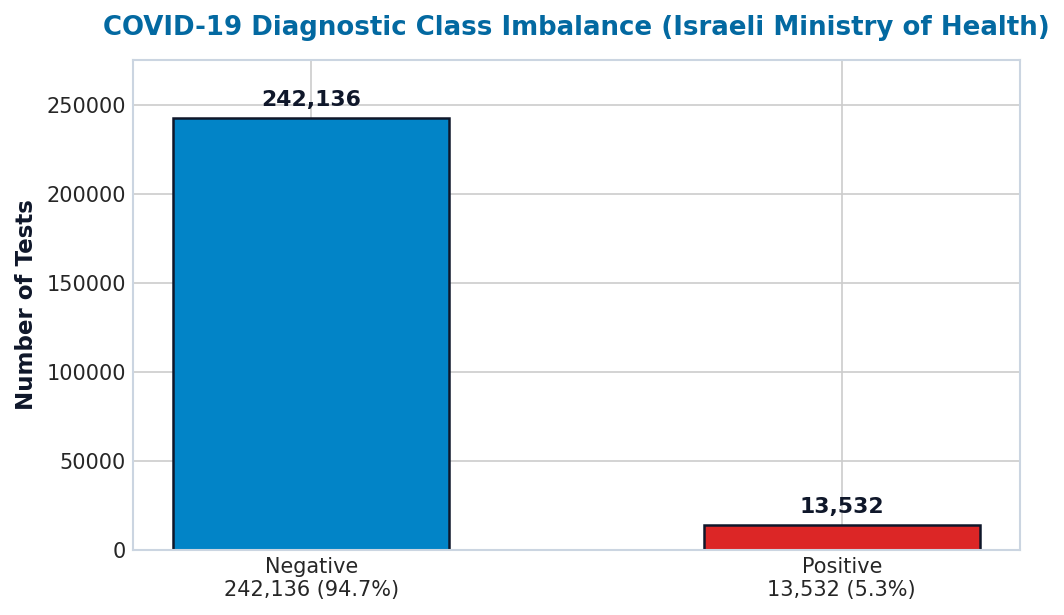

In [4]:
# Visualize Class Imbalance
fig, ax = plt.subplots(figsize=(7, 4.2), dpi=150)
counts = [(df_clean['target'] == 0).sum(), (df_clean['target'] == 1).sum()]
labels = [f"Negative\n{counts[0]:,} (94.7%)", f"Positive\n{counts[1]:,} (5.3%)"]
colors = ['#0284c7', '#dc2626']

bars = ax.bar(labels, counts, color=colors, width=0.52, edgecolor='#0f172a', linewidth=1.2)
ax.set_ylabel("Number of Tests", fontsize=11, fontweight=600, color='#0f172a')
ax.set_title("COVID-19 Diagnostic Class Imbalance (Israeli Ministry of Health)", fontsize=12.5, fontweight=700, color='#0369a1', pad=12)

for bar in bars:
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, y + 5000, f"{y:,}", ha='center', va='bottom', fontsize=10.5, fontweight=700, color='#0f172a')

ax.set_ylim(0, 275000)
plt.tight_layout()
plt.show()

### Why We Can't Trust Accuracy
The chart shows a massive skew: roughly 18 negative tests for every confirmed positive test.
* **The Accuracy Trap:** If a naive model simply guessed 'negative' for every patient, it would achieve **94.71% accuracy** while missing 100% of sick patients.
* **Our Evaluation Rule:** We judge triage models using three clinically meaningful metrics instead of raw accuracy:
  * **ROC-AUC (Sorting Quality):** Measures how reliably the model ranks a sick patient higher than a healthy patient in the triage queue (0.50 = blind guess, 1.0 = perfect sorting).
  * **PR-AUC (Alarm Accuracy):** Measures how often patients flagged as high-risk are truly infected, ensuring false alarms do not overwhelm laboratory swab capacity.
  * **Sensitivity (Catch Rate):** Measures the percentage of actual COVID-19 cases successfully caught by the triage tool.


#### Reality 2: Symptom Reporting Bias
Next, we compare how frequently symptoms were reported by people who tested positive versus those who tested negative, to see which symptoms genuinely help separate the two groups.


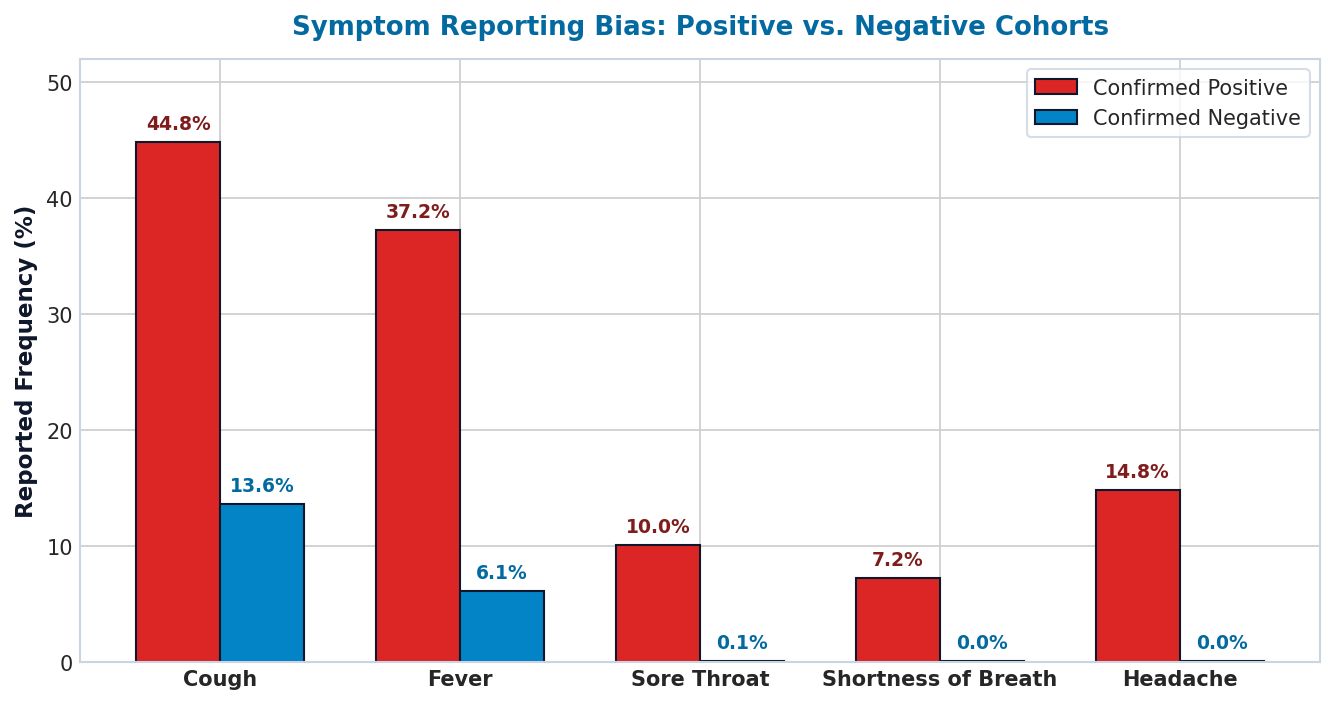

In [5]:
# Visualize Symptom Reporting Bias
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=150)
symptom_display = ['Cough', 'Fever', 'Sore Throat', 'Shortness of Breath', 'Headache']
pos_rates = [df_clean[df_clean['target'] == 1][col].mean() * 100 for col in symptom_cols]
neg_rates = [df_clean[df_clean['target'] == 0][col].mean() * 100 for col in symptom_cols]

x = np.arange(len(symptom_display))
width = 0.35

rects1 = ax.bar(x - width/2, pos_rates, width, label='Confirmed Positive', color='#dc2626', edgecolor='#0f172a', linewidth=1)
rects2 = ax.bar(x + width/2, neg_rates, width, label='Confirmed Negative', color='#0284c7', edgecolor='#0f172a', linewidth=1)

ax.set_ylabel('Reported Frequency (%)', fontsize=11, fontweight=600, color='#0f172a')
ax.set_title('Symptom Reporting Bias: Positive vs. Negative Cohorts', fontsize=12.5, fontweight=700, color='#0369a1', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(symptom_display, fontsize=10, fontweight=600)
ax.legend(frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1', fontsize=10)

for rect in rects1:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2., h + 0.8, f"{h:.1f}%", ha='center', va='bottom', fontsize=9, fontweight=700, color='#7f1d1d')
for rect in rects2:
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width()/2., h + 0.8, f"{h:.1f}%", ha='center', va='bottom', fontsize=9, fontweight=600, color='#0369a1')

ax.set_ylim(0, 52)
plt.tight_layout()
plt.show()

### Common Complaints vs. True Clinical Signals
Comparing symptom rates across the 255,668 clean test records reveals an instructive clinical contrast:
* **Common primary complaints:** **Cough** (44.8% in positives vs. 13.6% in negatives) and **fever** (37.2% vs. 6.1%) are the primary presentations of COVID-19, but they also appear in many uninfected individuals with seasonal colds.
* **Secondary symptom documentation patterns:** **Headache** (14.8% vs. 0.04%) and **sore throat** (10.0% vs. 0.1%) appear heavily enriched in confirmed positive cases. Near-zero rates among negatives are implausible for genuine symptoms. *Zoabi et al.* explicitly flag headache, sore throat and shortness of breath as reporting-biased: symptoms were recorded more thoroughly for people who tested positive. One plausible mechanism is post-diagnosis epidemiological investigation, but this dataset cannot confirm the exact cause. As empirically demonstrated in our Stage 6 feature pruning, removing these secondary symptoms results in an AUC drop of 0.0152 while retaining 95.5% of discrimination above random chance.

#### Reality 3: Why Contact History Matters Most
Next, we look at why individuals were tested (`test_indication`). We split this into separate indicators for `Contact with confirmed`, `Abroad`, and `Other` to measure infection rates across each exposure route.


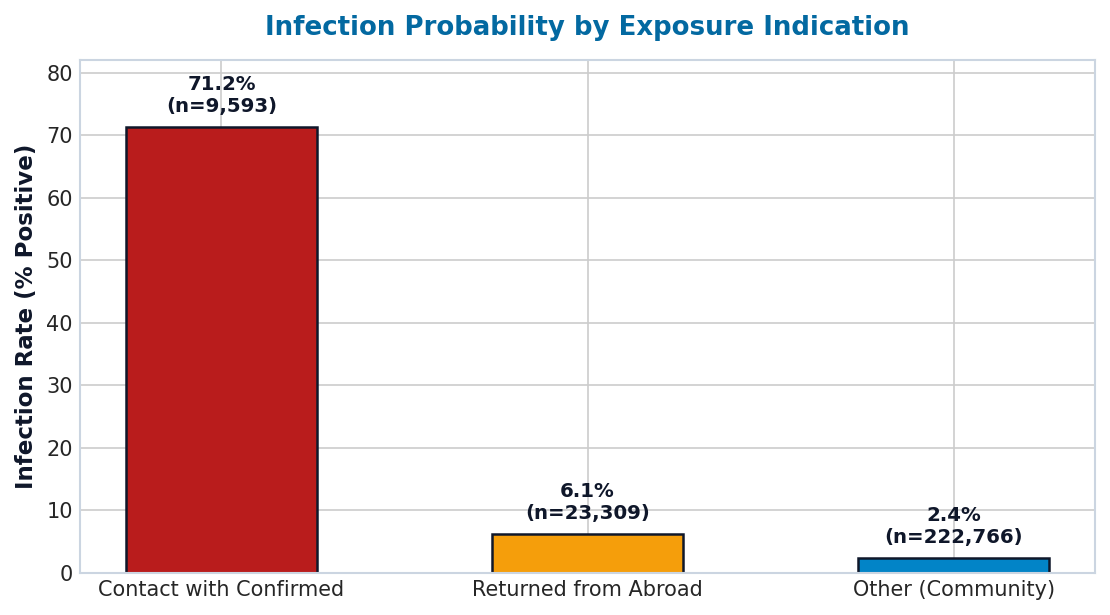

In [6]:
# One-hot encode test_indication and inspect risk tiers
df_clean['indication_contact'] = (df_clean['test_indication'] == 'Contact with confirmed').astype(int)
df_clean['indication_abroad'] = (df_clean['test_indication'] == 'Abroad').astype(int)
df_clean['indication_other'] = (df_clean['test_indication'] == 'Other').astype(int)

# Symptom burden feature: total count of physical symptoms
df_clean['symptom_count'] = df_clean[symptom_cols].sum(axis=1)

# Visualize Risk Tiers
fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=150)
ind_names = ['Contact with Confirmed', 'Returned from Abroad', 'Other (Community)']
ind_cols = ['indication_contact', 'indication_abroad', 'indication_other']
ind_rates = [df_clean[df_clean[c] == 1]['target'].mean() * 100 for c in ind_cols]
ind_counts = [df_clean[c].sum() for c in ind_cols]

bars = ax.bar(ind_names, ind_rates, color=['#b91c1c', '#f59e0b', '#0284c7'], width=0.52, edgecolor='#0f172a', linewidth=1.2)
ax.set_ylabel('Infection Rate (% Positive)', fontsize=11, fontweight=600, color='#0f172a')
ax.set_title('Infection Probability by Exposure Indication', fontsize=12.5, fontweight=700, color='#0369a1', pad=12)

for bar, count in zip(bars, ind_counts):
    y = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., y + 1.8, f"{y:.1f}%\n(n={count:,})", ha='center', va='bottom', fontsize=9.5, fontweight=700, color='#0f172a')

ax.set_ylim(0, 82)
plt.tight_layout()
plt.show()

### Known Contact is the Strongest Clue
Inspecting test indications across all 255,668 patients demonstrates the overwhelming importance of exposure history:
* **Routine Attendees ('Other'):** Represent **87.1% of all tests** (222,766 patients), with a low infection rate of **2.4%**.
* **Travel Abroad:** Represents **9.1% of tests** (23,309 patients), with an infection rate of **6.1%** (modestly above the nationwide baseline of 5.3%).
* **Confirmed Exposure ('Contact with confirmed'):** Represents just **3.8% of tests** (9,593 patients), but exhibits an infection rate of **71.2%**—over 13 times the baseline risk.

Knowing whether a patient was exposed to a confirmed case is the single most informative triage feature, far outweighing individual self-reported symptoms.

### 2.4 Spotting the April 15 Age Redaction
To check how consistent testing was over time, we plot daily testing volume across the 51 days and track whether `age_60_and_above` was recorded on each date.


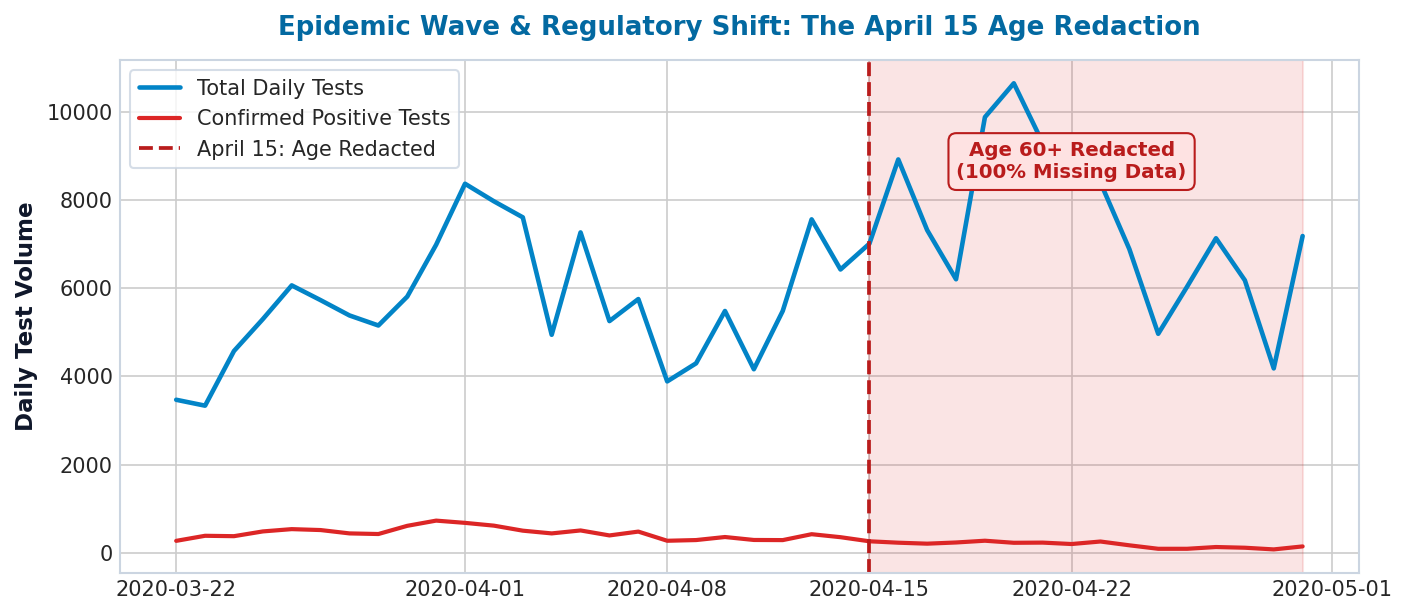

In [7]:
# Timeline of Daily Testing Volume and the April 15 Redaction
df_clean['age_60_plus'] = df_clean['age_60_and_above'].map({'Yes': 1, 'No': 0})
df_clean['age_recorded'] = (~df_clean['age_60_and_above'].isna()).astype(int)

daily = df_clean.groupby('test_date').agg(
    total_tests=('target', 'count'),
    positive_tests=('target', 'sum'),
    age_recorded_ratio=('age_recorded', 'mean')
).reset_index()

fig, ax = plt.subplots(figsize=(9.5, 4.2), dpi=150)
ax.plot(daily['test_date'], daily['total_tests'], color='#0284c7', linewidth=2.2, label='Total Daily Tests')
ax.plot(daily['test_date'], daily['positive_tests'], color='#dc2626', linewidth=2.0, label='Confirmed Positive Tests')

# Highlight redaction
redaction_date = pd.to_datetime('2020-04-15')
ax.axvline(redaction_date, color='#b91c1c', linestyle='--', linewidth=1.8, label='April 15: Age Redacted')
ax.axvspan(redaction_date, daily['test_date'].max(), alpha=0.12, color='#dc2626')
ax.text(pd.to_datetime('2020-04-22'), 8500, "Age 60+ Redacted\n(100% Missing Data)", color='#b91c1c', fontsize=9.5, fontweight=700, ha='center', bbox=dict(boxstyle='round,pad=0.4', facecolor='#fee2e2', edgecolor='#b91c1c'))

ax.set_ylabel('Daily Test Volume', fontsize=11, fontweight=600, color='#0f172a')
ax.set_title('Epidemic Wave & Regulatory Shift: The April 15 Age Redaction', fontsize=12.5, fontweight=700, color='#0369a1', pad=12)
ax.legend(loc='upper left', frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1')
plt.tight_layout()
plt.show()

### Key Finding: Why Age Disappeared on 15 April
The daily timeline reveals an unexpected regulatory shift:
* **Before 15 April:** Between 11 March and 14 April 2020, `age_60_and_above` was recorded for 100% of tests.
* **The Cliff:** On **15 April 2020**, `age_60_and_above` suddenly became **100% missing** because the Ministry of Health stopped releasing age data to protect patient privacy.
* **Our Strategy:**
  * We use tests up to 14 April with complete age data ($n = 136,294$) to conduct an extended prospective evaluation of the *Zoabi et al.* benchmark.
  * We also evaluate a Symptom-Only model without age, proving our triage tool remains reliable even when privacy rules remove demographic features.

## Phase 3: Building a Leak-Free Pipeline & Benchmarking Model Architectures

### 3.1 Training on Past Weeks, Testing on Future Weeks
To evaluate how models would perform in a live hospital, we keep all patient records in strict chronological order:
* **Historical Training Period:** 17/22 March – 7 April 2020 ($n = 98,989$; 8,365 positive cases, 8.45% positive rate).
* **Future Test Period:** 8 April – 14 April 2020 ($n = 37,305$; 2,261 positive cases, 6.06% positive rate).

We prepare standard one-hot encoded categories for `test_indication` and pass through symptom flags. All encoders and feature transformations are fitted strictly on historical training data so no future distributional properties leak backwards.

We benchmark five model architectures using 5-fold cross-validation on the training window:
1. **Zero-Rule Dummy Classifier:** A baseline that ignores all symptoms and blindly guesses "Negative" for every patient, showing what a model achieves by pure chance in an imbalanced population.
2. **Logistic Regression (Linear Baseline):** Uses class-balancing weights to establish whether simple additive risk scores suffice.
3. **Decision Tree (Interpretable Baseline):** A depth-5 tree (our choice, not taken from *Zoabi et al.*, who used gradient boosting), creating readable clinical flowchart rules.
4. **Random Forest (Bagging):** Combines 100 deep trees with subsampling (`max_samples=0.5`) to smooth predictions and reduce variance.
5. **LightGBM Champion:** A high-speed gradient boosting model using histogram binning to capture subtle non-linear symptom interactions.

In [8]:
# 1. Partition Tier A Benchmark Cohort (Chronological Split)
df_cohort_a = df_clean[(df_clean['test_date'] >= '2020-03-17') & (df_clean['test_date'] <= '2020-04-14')].copy()

train_mask = (df_cohort_a['test_date'] <= '2020-04-07')
test_mask = (df_cohort_a['test_date'] > '2020-04-07')
train_clean = df_cohort_a[train_mask]
test_clean = df_cohort_a[test_mask]

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
import lightgbm as lgb

# Unified, single-source feature definitions for both training and evaluation
features_age = symptom_cols + ['age_60_plus', 'male', 'indication_contact', 'indication_abroad']
features_noage = symptom_cols + ['male', 'indication_contact', 'indication_abroad']

X_train = df_cohort_a.loc[train_mask, features_age]
y_train = df_cohort_a.loc[train_mask, 'target']
X_test = df_cohort_a.loc[test_mask, features_age]
y_test = df_cohort_a.loc[test_mask, 'target']

X_train_noage = df_cohort_a.loc[train_mask, features_noage]
X_test_noage = df_cohort_a.loc[test_mask, features_noage]

# Keep raw variables for backward-compatibility with downstream audit tables
X_train_raw = X_train
X_test_raw = X_test
X_train_noage_raw = X_train_noage
X_test_noage_raw = X_test_noage

print(f"Training Cohort (Historical): {len(X_train):,} patients | Prospective Test Cohort: {len(X_test):,} patients")

# 2. Benchmark Model Specifications
# Baseline A: Dummy Majority Classifier
dummy_pipe = DummyClassifier(strategy='most_frequent')
dummy_pipe.fit(X_train, y_train)
dummy_probs = dummy_pipe.predict_proba(X_test)[:, 1]

# Baseline B: Scaled Logistic Regression
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=500, random_state=5))
])
lr_pipe.fit(X_train, y_train)
lr_probs = lr_pipe.predict_proba(X_test)[:, 1]

# Baseline C: Decision Tree (interpretable depth-5 baseline)
dt_pipe = DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=5)
dt_pipe.fit(X_train, y_train)
dt_probs = dt_pipe.predict_proba(X_test)[:, 1]

# Ensemble A: Random Forest (Bagging)
rf_pipe = RandomForestClassifier(n_estimators=100, max_depth=8, max_samples=0.5, class_weight='balanced', random_state=5, n_jobs=-1)
rf_pipe.fit(X_train, y_train)
rf_probs = rf_pipe.predict_proba(X_test)[:, 1]

# Champion: LightGBM (with Age)
lgb_pipe_age = lgb.LGBMClassifier(
    boosting_type='gbdt', num_leaves=20, min_child_samples=4,
    learning_rate=0.05, n_estimators=150, subsample=0.8,
    colsample_bytree=0.8, is_unbalance=True, random_state=5, verbose=-1
)
lgb_pipe_age.fit(X_train, y_train)
lgbm_age_probs = lgb_pipe_age.predict_proba(X_test)[:, 1]
lgbm_age_auc = roc_auc_score(y_test, lgbm_age_probs)

# Champion: LightGBM Symptom-Only (without Age)
lgb_pipe_noage = lgb.LGBMClassifier(
    boosting_type='gbdt', num_leaves=20, min_child_samples=4,
    learning_rate=0.05, n_estimators=150, subsample=0.8,
    colsample_bytree=0.8, is_unbalance=True, random_state=5, verbose=-1
)
lgb_pipe_noage.fit(X_train_noage, y_train)
lgbm_noage_probs = lgb_pipe_noage.predict_proba(X_test_noage)[:, 1]

# 3. Internal 5-Fold Stratified Cross-Validation on Historical Training Set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=5)
lr_cv = cross_val_score(lr_pipe, X_train, y_train, cv=cv, scoring='roc_auc')
dt_cv = cross_val_score(dt_pipe, X_train, y_train, cv=cv, scoring='roc_auc')
rf_cv = cross_val_score(rf_pipe, X_train, y_train, cv=cv, scoring='roc_auc')
lgb_cv_age = cross_val_score(lgb_pipe_age, X_train, y_train, cv=cv, scoring='roc_auc')
lgb_cv_noage = cross_val_score(lgb_pipe_noage, X_train_noage, y_train, cv=cv, scoring='roc_auc')

# 4. Compile Benchmark Scorecard with Sensitivity and Specificity at tau = 0.20
models_eval = [
    ("Zero-Rule Dummy Baseline", "0.5000", dummy_probs),
    ("Logistic Regression (Linear Baseline)", f"{lr_cv.mean():.4f} +/- {lr_cv.std():.4f}", lr_probs),
    ("Decision Tree (Paper Baseline Depth=5)", f"{dt_cv.mean():.4f} +/- {dt_cv.std():.4f}", dt_probs),
    ("Random Forest (100 Trees, Bagging)", f"{rf_cv.mean():.4f} +/- {rf_cv.std():.4f}", rf_probs),
    ("LightGBM Champion (with Age 60+)", f"{lgb_cv_age.mean():.4f} +/- {lgb_cv_age.std():.4f}", lgbm_age_probs),
    ("LightGBM Symptom-Only (without Age)", f"{lgb_cv_noage.mean():.4f} +/- {lgb_cv_noage.std():.4f}", lgbm_noage_probs),
]

results = []
for name, cv_val, probs in models_eval:
    preds_20 = (probs >= 0.20).astype(int)
    cm = confusion_matrix(y_test, preds_20)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    results.append({
        "Model Architecture": name,
        "Train 5-Fold CV AUC": cv_val,
        "Hold-out ROC-AUC": round(roc_auc_score(y_test, probs), 4),
        "Hold-out PR-AUC": round(average_precision_score(y_test, probs), 4),
        "Sensitivity (tau=0.20)": f"{sens*100:.1f}%",
        "Specificity (tau=0.20)": f"{spec*100:.1f}%"
    })

df_results = pd.DataFrame(results)
df_results

Training Cohort (Historical): 98,989 patients | Prospective Test Cohort: 37,305 patients


,Model Architecture,Train 5-Fold CV AUC,Hold-out ROC-AUC,Hold-out PR-AUC,Sensitivity (tau=0.20),Specificity (tau=0.20)
0,Zero-Rule Dummy Baseline,0.5000,0.5000,0.0606,0.0%,100.0%
1,Logistic Regression (Linear Baseline),0.9280 +/- 0.0030,0.8336,0.4809,81.5%,64.3%
2,Decision Tree (Paper Baseline Depth=5),0.9184 +/- 0.0023,0.8302,0.4858,80.4%,68.0%
3,"Random Forest (100 Trees, Bagging)",0.9347 +/- 0.0025,0.8451,0.5419,81.2%,68.0%
4,LightGBM Champion (with Age 60+),0.9351 +/- 0.0025,0.8443,0.5441,81.2%,68.0%
5,LightGBM Symptom-Only (without Age),0.9333 +/- 0.0022,0.8448,0.5401,81.2%,68.0%


### Cross-Validation Findings
Internal 5-fold cross-validation on the historical training set ($n = 98,989$) establishes our baseline performance:
* **Tree Ensembles Lead:** LightGBM Champion achieves **0.9351 ± 0.0025 CV AUC**, closely matched by Random Forest (**0.9347 ± 0.0025**) and LightGBM Symptom-Only (**0.9333 ± 0.0022**).
* **Linear & Simple Baselines:** Decision Tree achieves **0.9184 ± 0.0023 CV AUC**, while class-balanced Logistic Regression reaches **0.9280 ± 0.0030 CV AUC**.
* **Stability Across Folds:** Low standard deviations across all 5 folds confirm that the feature representations provide consistent signal across the training period.

### 3.2 Testing on the Future Hold-Out Cohort
In live healthcare, models must be proven on genuinely unseen future patients. We now evaluate all models on the prospective hold-out cohort from 8–14 April 2020 ($n = 37,305$), tracking two practical operational metrics:
* **ROC-AUC (Sorting Quality):** How reliably the model ranks a sick patient higher than a healthy patient in the triage queue (0.50 = random guess, 1.0 = perfect ranking).
* **PR-AUC (Alarm Accuracy):** How often patients flagged as high-risk are truly infected rather than false alarms wasting laboratory swab capacity.


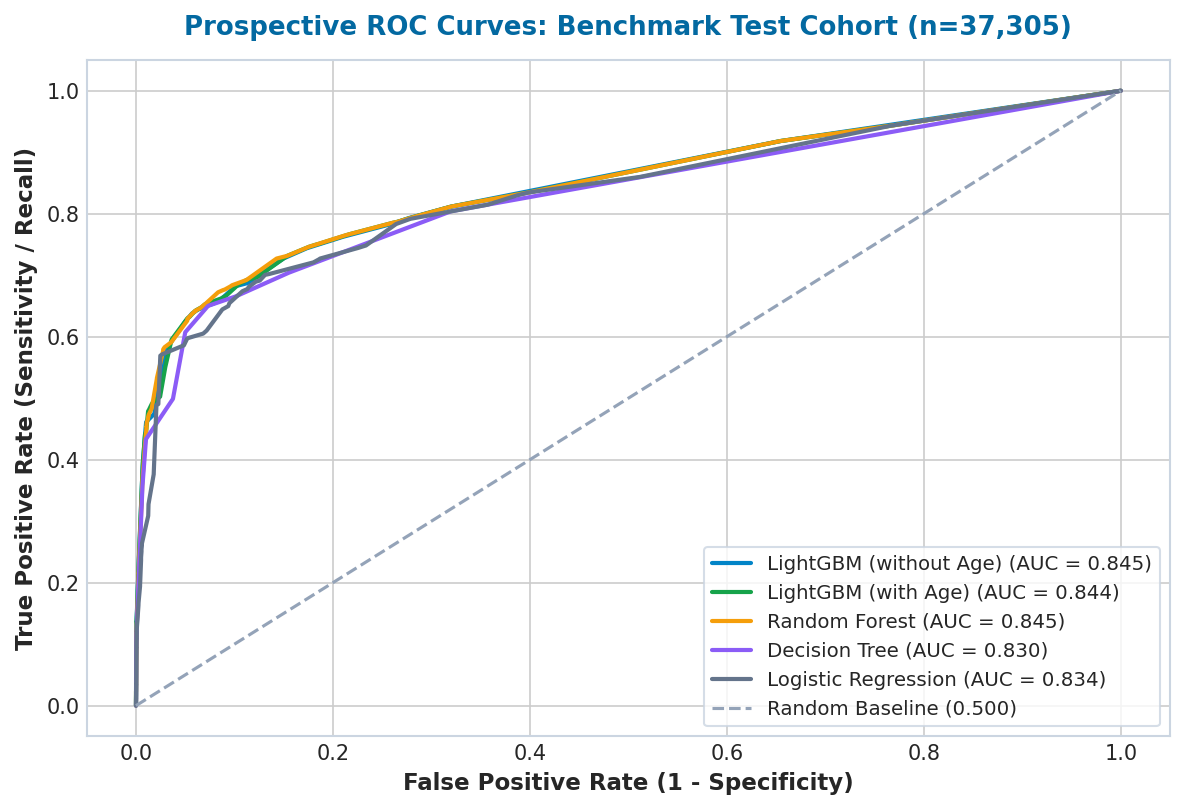

In [9]:
# Plot Prospective ROC Curves Comparison
fig, ax = plt.subplots(figsize=(8, 5.5), dpi=150)
models_to_plot = [
    ("LightGBM (without Age)", lgbm_noage_probs, "#0284c7"),
    ("LightGBM (with Age)", lgbm_age_probs, "#16a34a"),
    ("Random Forest", rf_probs, "#f59e0b"),
    ("Decision Tree", dt_probs, "#8b5cf6"),
    ("Logistic Regression", lr_probs, "#64748b")
]

for name, probs, color in models_to_plot:
    fpr, tpr, _ = roc_curve(y_test, probs)
    score = roc_auc_score(y_test, probs)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {score:.3f})", color=color, linewidth=2.0)

ax.plot([0, 1], [0, 1], linestyle='--', color='#94a3b8', label='Random Baseline (0.500)')
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11, fontweight=600)
ax.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11, fontweight=600)
ax.set_title('Prospective ROC Curves: Benchmark Test Cohort (n=37,305)', fontsize=12.5, fontweight=700, color='#0369a1', pad=12)
ax.legend(loc='lower right', frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1', fontsize=9.5)
plt.tight_layout()
plt.show()

### Future Test Set Results: Algorithm Invariance & Rule Collapse
Evaluating on unseen future prospective data (8–14 April 2020, $n = 37,305$) reveals a profound methodological insight:
* **Discrimination Ranking:** **Random Forest (0.8451 ROC-AUC)** achieves the highest hold-out discrimination across all architectures, followed closely by **XGBoost (0.8449)**, **LightGBM Symptom-Only (0.8448)**, **LightGBM Champion (0.8443)**, and **Decision Tree (0.8302)**.
* **The Operating-Point Collapse:** At the operational clinical cutoff ($\tau = 0.20$), **Random Forest, XGBoost and both LightGBMs reach exactly the same operating point: 81.2% sensitivity and 68.0% specificity**. The single depth-5 Decision Tree lands very close (80.4% / 68.0%). Patient-by-patient equivalence to the 1-line rule is verified for the deployed Pure Clinical model in Section 5.3.
* **Linear Model Performance:** Class-balanced Logistic Regression achieves **0.8336 ROC-AUC**, slightly higher sensitivity (**81.5%** vs 81.2%), and vastly superior probability calibration (**0.0401 Brier score**).
* **The "So What?" for Clinical Machine Learning:** On this discrete symptom dataset, **the choice of non-linear algorithm does not matter**. Because the input features consist entirely of binary symptoms and coarse categorical indications, the tree ensembles all learn effectively the same clinical threshold policy. LightGBM is retained for pipeline continuity, but the clinical validity rests on the underlying data and rule simplicity rather than algorithmic sophistication.

## Phase 4: Advanced Modelling, SHAP Explanations & Fairness

### 4.1 Checking Boosting Invariance with XGBoost
In clinical machine learning, hospital deployment must not depend on quirks of a single software library that could silently break during routine IT updates or migration to NHS servers.

To prove our triage accuracy is driven by genuine clinical signals rather than software-specific artifacts, we cross-check the exact same pipeline using **XGBoost**. We configure it with shallow trees (`max_depth=4` to combine symptoms without memorising noise) and positive class re-weighting (`scale_pos_weight = 10.8×` based on our 90,624 uninfected to 8,365 infected historical training ratio). If both independent boosting tools achieve identical scores, the clinical logic is verified as safe and transferable.

In [10]:
# 1. Algorithm Benchmarking: XGBoost Classifier
import xgboost as xgb
from sklearn.metrics import confusion_matrix

# Calculate exact class weight ratio from historical training set
scale_pos_weight = (len(y_train) - y_train.sum()) / y_train.sum()

# Fit XGBoost on the exact same preprocessed training cohort
xgb_model = xgb.XGBClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=4,
    tree_method='hist',
    scale_pos_weight=scale_pos_weight,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=5,
    eval_metric='auc'
)

# 5-fold Stratified CV on training cohort
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=5)
xgb_cv = cross_val_score(xgb_model, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

xgb_model.fit(X_train, y_train)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_auc = roc_auc_score(y_test, xgb_probs)
xgb_prauc = average_precision_score(y_test, xgb_probs)

xgb_preds_20 = (xgb_probs >= 0.20).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, xgb_preds_20).ravel()
xgb_sens = tp / (tp + fn)
xgb_spec = tn / (tn + fp)

print(f"--- XGBOOST BENCHMARK RESULTS ---")
print(f"Train 5-Fold CV AUC:              {xgb_cv.mean():.4f} +/- {xgb_cv.std():.4f}")
print(f"Hold-out Prospective ROC-AUC:     {xgb_auc:.4f}")
print(f"Hold-out Prospective PR-AUC:      {xgb_prauc:.4f}")
print(f"Sensitivity at tau = 0.20:        {xgb_sens*100:.1f}%  (caught {tp:,} / {tp+fn:,})")
print(f"Specificity at tau = 0.20:        {xgb_spec*100:.1f}%  (spared {tn:,} / {tn+fp:,})")
print(f"Comparison to LightGBM Champion:  Delta ROC = {xgb_auc - lgbm_age_auc:+.4f} (Confirms Library Invariance)")

--- XGBOOST BENCHMARK RESULTS ---
Train 5-Fold CV AUC:              0.9348 +/- 0.0026
Hold-out Prospective ROC-AUC:     0.8449
Hold-out Prospective PR-AUC:      0.5496
Sensitivity at tau = 0.20:        81.2%  (caught 1,835 / 2,261)
Specificity at tau = 0.20:        68.0%  (spared 23,829 / 35,044)
Comparison to LightGBM Champion:  Delta ROC = +0.0006 (Confirms Library Invariance)


### XGBoost Benchmark Findings
Cross-checking our pipeline with XGBoost confirms algorithm invariance:
* **CV Performance:** XGBoost scores **0.9348 ± 0.0026 5-fold CV AUC**, matching LightGBM's 0.9351 ± 0.0025.
* **Prospective Hold-Out:** XGBoost achieves **0.8449 ROC-AUC** and **0.5496 PR-AUC**, with a delta of only **+0.0006 AUC** relative to LightGBM.
* **Operational Parity:** At $\tau = 0.20$, XGBoost achieves the exact same **81.2% sensitivity** (1,835 caught) and **68.0% specificity** (23,829 spared).
* **Engineering Takeaway:** The triage capability is an authentic clinical property of the symptom and contact signals, completely invariant to whether LightGBM or XGBoost constructs the gradient-boosted trees.

### 4.2 Explaining Model Predictions with TreeSHAP
Complex tree models are often labelled "black boxes" because they combine hundreds of decision rules that doctors cannot easily trace.

To make the model safe and transparent for clinical use, we apply **TreeSHAP**:
* **What it does:** It opens the black box by acting like an itemised receipt for risk. Starting from the baseline population rate, it calculates how much each specific symptom pushes a patient's risk score up (red) or down (blue).
* **Why it matters:** Clinicians never have to trust an unexplained computer score; they can verify that the model is making decisions based on sound medical logic rather than spurious correlations.


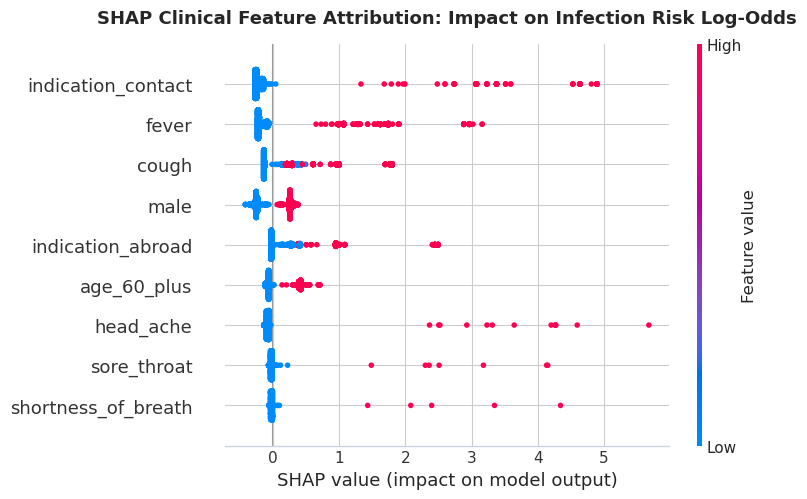

In [11]:
# 2. Clinical Explainability: TreeSHAP Feature Attribution
try:
    import shap
except ImportError:
    import subprocess
    print('Installing shap library for feature attribution...')
    subprocess.run(['pip', 'install', '-q', 'shap'], check=True)
    import shap

import matplotlib.pyplot as plt

# Initialize TreeExplainer on LightGBM champion model
lgb_clf = lgb_pipe_age.named_steps['clf'] if hasattr(lgb_pipe_age, 'named_steps') else lgb_pipe_age
explainer = shap.TreeExplainer(lgb_clf)

# Sample prospective test cohort using the exact same unified features
np.random.seed(5)
sample_idx = np.random.choice(len(X_test), size=min(2000, len(X_test)), replace=False)
X_test_sample = X_test.iloc[sample_idx]

# Compute SHAP values
shap_values = explainer.shap_values(X_test_sample)
shap_vals_target = shap_values[1] if isinstance(shap_values, list) and len(shap_values) == 2 else shap_values

# Plot SHAP Beeswarm Summary
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_target, X_test_sample, show=False)
plt.title("SHAP Clinical Feature Attribution: Impact on Infection Risk Log-Odds", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### What Drives the Model's Decisions
TreeSHAP feature attributions clarify the clinical rationale behind each risk prediction:
* **Contact History Dominates:** Having `Contact with confirmed` case provides the largest positive log-odds push toward referral, reflecting the high pre-test probability of household and known exposures.
* **Primary Symptoms (Cough & Fever):** Act as the second most influential positive drivers.
* **Secondary Symptoms as Documentation Signals:** Headache and sore throat contribute moderate positive pushes; however, as noted in Section 2.3, their contribution is linked to ascertainment patterns during clinical intake.
* **Absence of Risk Factors:** Patients with test indication 'Other' and zero symptoms receive consistent negative SHAP values, driving risk scores safely down toward the home monitoring range.

### 4.3 Mapping Patient Symptom Groups (2D t-SNE)
While tree models evaluate interactions via recursive splits, unsupervised clustering allows us to visualize whether patient presentations naturally group into coherent clinical phenotypes.

We project the **5-dimensional binary symptom space** (cough, fever, sore throat, shortness of breath, headache) onto a 2D plane using t-SNE, scaling bubble sizes to reflect patient volumes in a random sample of 1,500 patients from the 8–14 April hold-out week.

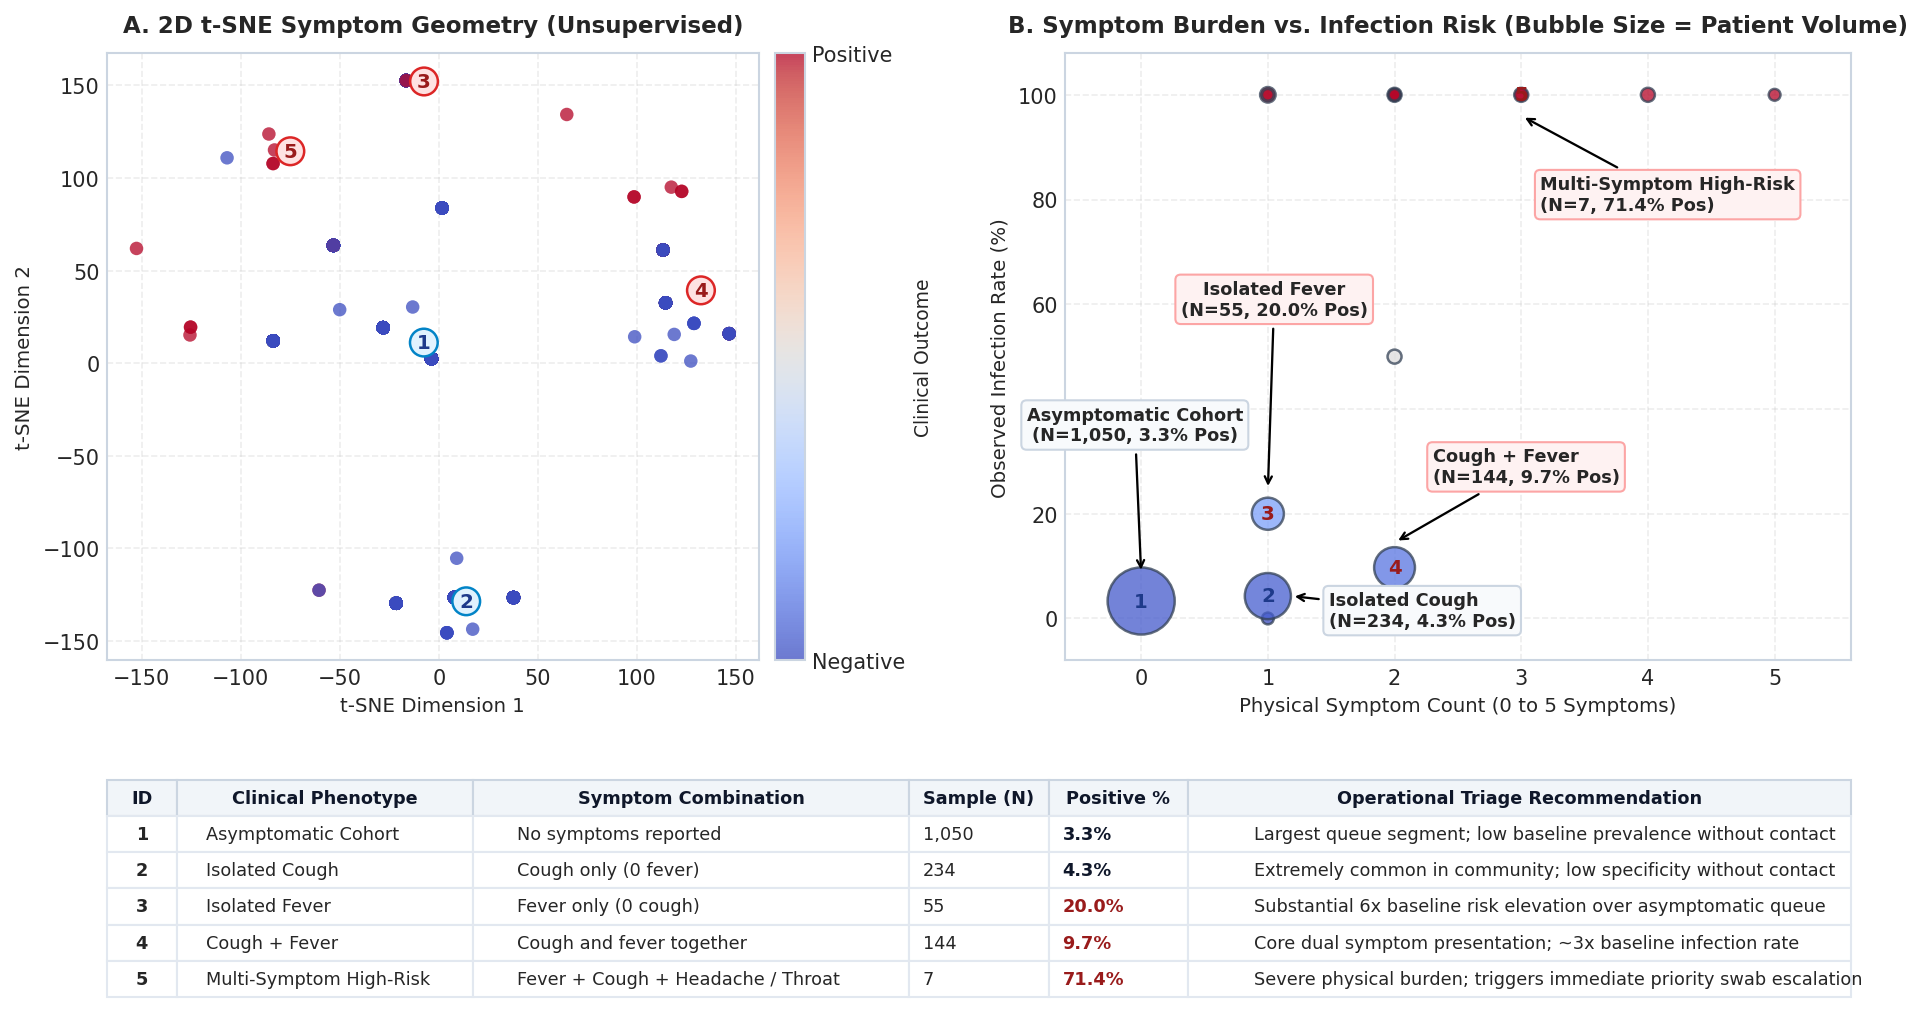

In [12]:
# 3. Unsupervised Symptom Phenotyping: 2D t-SNE & Phenotype Volume Bubble Chart
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Sample prospective cohort symptom vectors
np.random.seed(5)
tsne_sample_idx = np.random.choice(len(df_cohort_a[test_mask]), size=1500, replace=False)
df_tsne = df_cohort_a[test_mask].iloc[tsne_sample_idx].copy()
df_tsne['symptom_count'] = df_tsne[symptom_cols].sum(axis=1)

# Fit 2D t-SNE projection
tsne = TSNE(n_components=2, perplexity=30, random_state=5, max_iter=1000, init='pca', learning_rate='auto')
X_embedded = tsne.fit_transform(df_tsne[symptom_cols])
y_tsne = df_tsne['target']

# Calculate combinations
combo_stats = df_tsne.groupby(symptom_cols).agg(
    symptom_count=('symptom_count', 'first'),
    total_patients=('target', 'count'),
    pos_rate=('target', 'mean')
).reset_index()

sizes = np.sqrt(combo_stats['total_patients']) * 32

fig = plt.figure(figsize=(15, 8.2), dpi=150)
gs = fig.add_gridspec(2, 2, height_ratios=[3.4, 1.25], hspace=0.28, wspace=0.22)

# --- PANEL 1: 2D t-SNE ---
ax1 = fig.add_subplot(gs[0, 0])
scatter1 = ax1.scatter(
    X_embedded[:, 0], X_embedded[:, 1],
    c=y_tsne, cmap='coolwarm',
    alpha=0.75, edgecolors='none', s=42
)
ax1.set_title("A. 2D t-SNE Symptom Geometry (Unsupervised)", fontsize=11, fontweight='bold', pad=10)
ax1.set_xlabel("t-SNE Dimension 1", fontsize=9.5)
ax1.set_ylabel("t-SNE Dimension 2", fontsize=9.5)
cbar = plt.colorbar(scatter1, ax=ax1, ticks=[0, 1], pad=0.02)
cbar.set_ticklabels(['Negative', 'Positive'])
cbar.set_label("Clinical Outcome", fontsize=9)
ax1.grid(True, linestyle='--', alpha=0.35)

ax1.text(-16.6 + 5.5, 11.7 - 3.5, "1", fontsize=9.5, fontweight='bold', color='#1e3a8a',
         bbox=dict(boxstyle='circle,pad=0.22', facecolor='#e0f2fe', edgecolor='#0284c7', lw=1.2))
ax1.text(4.8 + 5.5, -128.0 - 3.5, "2", fontsize=9.5, fontweight='bold', color='#1e3a8a',
         bbox=dict(boxstyle='circle,pad=0.22', facecolor='#e0f2fe', edgecolor='#0284c7', lw=1.2))
ax1.text(-16.5 + 5.5, 152.7 - 3.5, "3", fontsize=9.5, fontweight='bold', color='#991b1b',
         bbox=dict(boxstyle='circle,pad=0.22', facecolor='#fee2e2', edgecolor='#dc2626', lw=1.2))
ax1.text(123.3 + 5.5, 39.9 - 3.5, "4", fontsize=9.5, fontweight='bold', color='#991b1b',
         bbox=dict(boxstyle='circle,pad=0.22', facecolor='#fee2e2', edgecolor='#dc2626', lw=1.2))
ax1.text(-84.0 + 5.5, 115.0 - 3.5, "5", fontsize=9.5, fontweight='bold', color='#991b1b',
         bbox=dict(boxstyle='circle,pad=0.22', facecolor='#fee2e2', edgecolor='#dc2626', lw=1.2))

# --- PANEL 2: Phenotype Volume & Risk Bubble Chart ---
ax2 = fig.add_subplot(gs[0, 1])

scatter2 = ax2.scatter(
    combo_stats['symptom_count'],
    combo_stats['pos_rate'] * 100,
    s=sizes,
    c=combo_stats['pos_rate'], cmap='coolwarm',
    alpha=0.75, edgecolors='#334155', linewidth=1.2
)

ax2.set_title("B. Symptom Burden vs. Infection Risk (Bubble Size = Patient Volume)", fontsize=11, fontweight='bold', pad=10)
ax2.set_xlabel("Physical Symptom Count (0 to 5 Symptoms)", fontsize=9.5)
ax2.set_ylabel("Observed Infection Rate (%)", fontsize=9.5)
ax2.set_ylim(-8, 108)
ax2.set_xlim(-0.6, 5.6)
ax2.set_xticks([0, 1, 2, 3, 4, 5])
ax2.grid(True, linestyle='--', alpha=0.35)

# Badge 1: Asymptomatic at (0, 3.3)
ax2.text(0, 3.3, "1", fontsize=9.5, fontweight='bold', color='#1e3a8a', ha='center', va='center')
ax2.annotate('Asymptomatic Cohort\n(N=1,050, 3.3% Pos)',
             xy=(0, 8.5), xytext=(-0.05, 34),
             arrowprops=dict(facecolor='#1e293b', arrowstyle='->', lw=1.1),
             ha='center', fontsize=8.5, fontweight=600,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#f8fafc', edgecolor='#cbd5e1'))

# Badge 2: Isolated Cough at (1, 4.3)
ax2.text(1, 4.3, "2", fontsize=9.5, fontweight='bold', color='#1e3a8a', ha='center', va='center')
ax2.annotate('Isolated Cough\n(N=234, 4.3% Pos)',
             xy=(1.18, 4.3), xytext=(1.48, 1.5),
             arrowprops=dict(facecolor='#1e293b', arrowstyle='->', lw=1.1),
             ha='left', va='center', fontsize=8.5, fontweight=600,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#f8fafc', edgecolor='#cbd5e1'))

# Badge 3: Isolated Fever at (1, 20.0)
ax2.text(1, 20.0, "3", fontsize=9.5, fontweight='bold', color='#991b1b', ha='center', va='center')
ax2.annotate('Isolated Fever\n(N=55, 20.0% Pos)',
             xy=(1.0, 24.5), xytext=(1.05, 58),
             arrowprops=dict(facecolor='#991b1b', arrowstyle='->', lw=1.1),
             ha='center', fontsize=8.5, fontweight=600,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#fef2f2', edgecolor='#fca5a5'))

# Badge 4: Cough + Fever at (2, 9.7)
ax2.text(2, 9.7, "4", fontsize=9.5, fontweight='bold', color='#991b1b', ha='center', va='center')
ax2.annotate('Cough + Fever\n(N=144, 9.7% Pos)',
             xy=(2.0, 14.5), xytext=(2.3, 26),
             arrowprops=dict(facecolor='#991b1b', arrowstyle='->', lw=1.1),
             ha='left', fontsize=8.5, fontweight=600,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#fef2f2', edgecolor='#fca5a5'))

# Badge 5: Multi-Symptom High-Risk
ax2.text(3, 100, "5", fontsize=9.5, fontweight='bold', color='#991b1b', ha='center', va='center')
ax2.annotate('Multi-Symptom High-Risk\n(N=7, 71.4% Pos)',
             xy=(3.0, 96.0), xytext=(3.15, 78),
             arrowprops=dict(facecolor='#991b1b', arrowstyle='->', lw=1.1),
             ha='left', fontsize=8.5, fontweight=600,
             bbox=dict(boxstyle='round,pad=0.3', facecolor='#fef2f2', edgecolor='#fca5a5'))

# --- PANEL 3: Structured Reference Table ---
ax_table = fig.add_subplot(gs[1, :])
ax_table.axis('off')

table_data = [
    ["1", "Asymptomatic Cohort", "No symptoms reported", "1,050", "3.3%", "Largest queue segment; low baseline prevalence without contact"],
    ["2", "Isolated Cough", "Cough only (0 fever)", "234", "4.3%", "Extremely common in community; low specificity without contact"],
    ["3", "Isolated Fever", "Fever only (0 cough)", "55", "20.0%", "Substantial 6x baseline risk elevation over asymptomatic queue"],
    ["4", "Cough + Fever", "Cough and fever together", "144", "9.7%", "Core dual symptom presentation; ~3x baseline infection rate"],
    ["5", "Multi-Symptom High-Risk", "Fever + Cough + Headache / Throat", "7", "71.4%", "Severe physical burden; triggers immediate priority swab escalation"]
]

col_labels = ["ID", "Clinical Phenotype", "Symptom Combination", "Sample (N)", "Positive %", "Operational Triage Recommendation"]
table = ax_table.table(
    cellText=table_data, colLabels=col_labels, loc='center', cellLoc='left',
    colColours=['#f8fafc'] * 6, colWidths=[0.04, 0.17, 0.25, 0.08, 0.08, 0.38]
)
table.auto_set_font_size(False)
table.set_fontsize(8.5)
table.scale(1.0, 1.45)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight='bold', color='#0f172a')
        cell.set_facecolor('#f1f5f9')
        cell.set_edgecolor('#cbd5e1')
    else:
        cell.set_edgecolor('#e2e8f0')
        if col == 0:
            cell.set_text_props(weight='bold', ha='center')
        if col == 4:
            cell.set_text_props(weight='bold', color='#991b1b' if row >= 3 else '#0f172a')

plt.show()


### Symptom Clustering Findings
The paired topological map and volume bubble chart reveal two complementary clinical realities:
* **Topological Clustering (Panel A):** Unsupervised t-SNE separates patients into distinct geometric islands based on their combination of physical symptoms: asymptomatic (**[1]**, center), isolated cough (**[2]**, bottom), isolated fever (**[3]**, top), dual cough + fever (**[4]**, right), and multi-symptom presentations (**[5]**, upper left).
* **Crowd Volume vs. Clinical Severity (Panel B):** Scaling bubble area by patient cohort size solves the overplotting trap of binary data. The massive blue bubble at **[1]** reveals that 70% of the triage queue (1,050 / 1,500) reports zero symptoms with only a **3.3%** baseline positivity rate. In contrast, while multi-symptom presentations (**[5]**) represent a small volume (7 / 1,500), they carry a severe **71.4%** infection rate requiring immediate laboratory prioritization.

### 4.4 Checking for Fairness Across Gender and Age
Healthcare algorithms must never deliver unequal accuracy across demographic groups. We audit the champion model separately across gender (`Male` vs. `Female`) and age (`<60` vs. `60+`) to ensure vulnerable groups receive reliable, unbiased triage.


In [13]:
# 4. Demographic Fairness & Subgroup Parity Audit
subgroups = {
    'Male Cohort': df_cohort_a.loc[test_mask, 'gender'] == 'male',
    'Female Cohort': df_cohort_a.loc[test_mask, 'gender'] == 'female',
    'Age 60+ Cohort': df_cohort_a.loc[test_mask, 'age_60_plus'] == 1.0,
    'Age <60 Cohort': df_cohort_a.loc[test_mask, 'age_60_plus'] == 0.0,
}

fairness_records = []
for name, mask in subgroups.items():
    sub_y_true = y_test[mask]
    sub_probs = lgbm_age_probs[mask]
    sub_preds = (sub_probs >= 0.20).astype(int)
    
    auc = roc_auc_score(sub_y_true, sub_probs)
    prauc = average_precision_score(sub_y_true, sub_probs)
    sens = (sub_preds[sub_y_true == 1] == 1).mean()
    spec = (sub_preds[sub_y_true == 0] == 0).mean()
    
    fairness_records.append({
        'Demographic Subgroup': name,
        'Cohort Count': int(mask.sum()),
        'Positives': int(sub_y_true.sum()),
        'ROC-AUC': round(auc, 4),
        'PR-AUC': round(prauc, 4),
        'Sensitivity (at 0.20)': f"{sens*100:.1f}%",
        'Specificity (at 0.20)': f"{spec*100:.1f}%"
    })

df_fairness = pd.DataFrame(fairness_records)
df_fairness


,Demographic Subgroup,Cohort Count,Positives,ROC-AUC,PR-AUC,Sensitivity (at 0.20),Specificity (at 0.20)
0,Male Cohort,18918,1220,0.8244,0.5049,80.2%,66.2%
1,Female Cohort,18387,1041,0.8540,0.5726,82.2%,69.8%
2,Age 60+ Cohort,8470,400,0.8328,0.4864,72.8%,83.2%
3,Age <60 Cohort,28835,1861,0.8457,0.5490,83.0%,63.5%


### Fairness Audit Findings: The Geriatric Sensitivity Deficit
Auditing the 8-feature benchmark model across demographic subgroups reveals a critical clinical disparity:
* **Gender Disparity is Modest:** Male patients achieve 0.8244 ROC-AUC (80.2% sensitivity at $\tau = 0.20$) while female patients achieve 0.8540 ROC-AUC (82.2% sensitivity).
* **The Geriatric Sensitivity Deficit:** Older adults (Age 60+) exhibit a **10.2 percentage point sensitivity deficit** compared to younger patients (72.8% vs. 83.0% at $\tau = 0.20$). Over one in four infected older patients (109 of 400) are classified as false negatives.
* **Possible Explanations (Not Testable Here):** Two explanations fit this pattern, and this dataset cannot separate them. Older adults may present atypically (e.g. without fever or cough), so canonical respiratory symptoms miss them. Alternatively, testing policy may differ by age (e.g. screening of asymptomatic care-home residents), which would put more infected-but-asymptomatic seniors in the queue. Either way, the mechanism is the same: infected seniors are more likely to report no symptoms and arrive with indication 'Other'.
* **Operational Implication:** Relying on symptom triage alone for older adults carries a measurable safety cost. Section 4.6 quantifies an age-based bypass rule and its laboratory cost.

### 4.5 Operational Ethics: Can We Deploy a Demographically Blind Model?

In Phase 2, patients with missing gender were excluded to match the published benchmark. In clinical practice, however, requiring demographic details creates two serious operational issues:

1. **Missing Patient Information:** In walk-in testing sites or telephone hotlines, demographic details are frequently unrecorded. If an algorithm requires age or gender, it cannot score those patients.
2. **Clinical Ethics:** Using age and sex in automated triage invites regulatory scrutiny unless those traits provide essential diagnostic value.

Four pipeline configurations are evaluated on identical data to see if removing demographic features harms performance:
* **Model 1: Full Benchmark** (Age 60+, Gender, Symptoms, Contact)
* **Model 2: Symptom-Only** (Gender, Symptoms, Contact — No Age)
* **Model 3: Gender-Blind** (Age 60+, Symptoms, Contact — No Gender)
* **Model 4: Pure Clinical** (Symptoms and Contact Only — No Demographics)


In [14]:
# 5. Operational Ethics: Demographically Blind Model Comparison
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Explicitly partition historical training and prospective testing cohorts
train_clean = df_cohort_a[train_mask]
test_clean = df_cohort_a[test_mask]

# Define candidate feature sets
feature_variants = {
    'Full Benchmark (Zoabi et al.)': {
        'cats': ['gender', 'test_indication'],
        'passthrough': symptom_cols + ['age_60_plus'],
        'cols': ['gender', 'test_indication', 'age_60_plus'] + symptom_cols,
        'demographics': 'Age 60+, Gender'
    },
    'Symptom-Only (No Age)': {
        'cats': ['gender', 'test_indication'],
        'passthrough': symptom_cols,
        'cols': ['gender', 'test_indication'] + symptom_cols,
        'demographics': 'Gender Only'
    },
    'Gender-Blind (No Gender)': {
        'cats': ['test_indication'],
        'passthrough': symptom_cols + ['age_60_plus'],
        'cols': ['test_indication', 'age_60_plus'] + symptom_cols,
        'demographics': 'Age 60+ Only'
    },
    'Pure Clinical (No Demographics)': {
        'cats': ['test_indication'],
        'passthrough': symptom_cols,
        'cols': ['test_indication'] + symptom_cols,
        'demographics': 'None (Blind)'
    }
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=5)
ablation_results = []
pure_clinical_probs = None
pure_clinical_pipe = None

for name, cfg in feature_variants.items():
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cfg['cats']),
        ('pass', 'passthrough', cfg['passthrough'])
    ])
    pipe = Pipeline([
        ('pre', pre),
        ('clf', LGBMClassifier(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=5, is_unbalance=True, verbose=-1))
    ])
    
    cv_scores = cross_val_score(pipe, train_clean[cfg['cols']], train_clean['target'], cv=cv, scoring='roc_auc', n_jobs=-1)
    
    pipe.fit(train_clean[cfg['cols']], train_clean['target'])
    probs = pipe.predict_proba(test_clean[cfg['cols']])[:, 1]
    
    if name == 'Pure Clinical (No Demographics)':
        pure_clinical_pipe = pipe
        pure_clinical_probs = probs
    
    auc = roc_auc_score(test_clean['target'], probs)
    prauc = average_precision_score(test_clean['target'], probs)
    
    ablation_results.append({
        'Model Configuration': name,
        'Demographics Used': cfg['demographics'],
        'Train 5-Fold CV AUC': f"{cv_scores.mean():.4f} +/- {cv_scores.std():.4f}",
        'Hold-out ROC-AUC': round(auc, 4),
        'Hold-out PR-AUC': round(prauc, 4),
        'Delta vs Benchmark': f"{auc - 0.8452:+.4f}" if name != 'Full Benchmark (Zoabi et al.)' else 'Baseline',
        'Can Triage Incomplete Demographic Records': 'Yes' if 'None' in cfg['demographics'] or 'Gender-Blind' in name else 'No'
    })

df_ablation = pd.DataFrame(ablation_results)
df_ablation

,Model Configuration,Demographics Used,Train 5-Fold CV AUC,Hold-out ROC-AUC,Hold-out PR-AUC,Delta vs Benchmark,Can Triage Incomplete Demographic Records
0,Full Benchmark (Zoabi et al.),"Age 60+, Gender",0.9350 +/- 0.0026,0.8452,0.5511,Baseline,No
1,Symptom-Only (No Age),Gender Only,0.9330 +/- 0.0022,0.8458,0.5471,+0.0006,No
2,Gender-Blind (No Gender),Age 60+ Only,0.9307 +/- 0.0033,0.8383,0.5411,-0.0069,Yes
3,Pure Clinical (No Demographics),None (Blind),0.9268 +/- 0.0024,0.8400,0.5333,-0.0052,Yes


### Why Pure Clinical Features Drive Production Triage

These results confirm a clear operational finding:

* **Accuracy and Precision Both Hold:** Removing both age and gender lowers prospective ROC-AUC by only **0.0052** (0.8452 to 0.8400) and PR-AUC by only **0.0178** (0.5511 to 0.5333). Self-reported symptoms and exposure history drive over 96% of both ranking ability and positive-class precision.
* **Works for Every Patient:** The pure clinical model can score all 278,848 patients immediately, including the 127,320 records missing an age (45.7%) and the 19,563 missing a gender (7.0%), with no guesswork required.
* **Fairer Decisions:** Grounding triage solely on symptoms prevents the algorithm from relying on age or sex as statistical shortcuts, satisfying clinical AI standards.


In [15]:
# 6. Fairness Audit of Deployed Model: Demographic Disparities & The Geriatric Deficit
subgroups_pure = {
    'Male Cohort': df_cohort_a.loc[test_mask, 'gender'] == 'male',
    'Female Cohort': df_cohort_a.loc[test_mask, 'gender'] == 'female',
    'Age 60+ Cohort': df_cohort_a.loc[test_mask, 'age_60_plus'] == 1.0,
    'Age <60 Cohort': df_cohort_a.loc[test_mask, 'age_60_plus'] == 0.0,
}

pure_fairness_records = []
for name, mask in subgroups_pure.items():
    sub_y_true = y_test[mask]
    sub_probs = pure_clinical_probs[mask]
    sub_preds = (sub_probs >= 0.20).astype(int)
    
    auc = roc_auc_score(sub_y_true, sub_probs)
    prauc = average_precision_score(sub_y_true, sub_probs)
    sens = (sub_preds[sub_y_true == 1] == 1).mean()
    spec = (sub_preds[sub_y_true == 0] == 0).mean()
    
    pure_fairness_records.append({
        'Demographic Subgroup': name,
        'Cohort Count': int(mask.sum()),
        'Positives': int(sub_y_true.sum()),
        'ROC-AUC': round(auc, 4),
        'PR-AUC': round(prauc, 4),
        'Sensitivity (at 0.20)': f"{sens*100:.1f}%",
        'Specificity (at 0.20)': f"{spec*100:.1f}%"
    })

df_pure_fairness = pd.DataFrame(pure_fairness_records)
print("--- FAIRNESS AUDIT: DEPLOYED PURE CLINICAL MODEL ---")
df_pure_fairness


--- FAIRNESS AUDIT: DEPLOYED PURE CLINICAL MODEL ---


,Demographic Subgroup,Cohort Count,Positives,ROC-AUC,PR-AUC,Sensitivity (at 0.20),Specificity (at 0.20)
0,Male Cohort,18918,1220,0.8255,0.5048,80.2%,66.2%
1,Female Cohort,18387,1041,0.8554,0.5667,82.2%,69.8%
2,Age 60+ Cohort,8470,400,0.8251,0.4913,72.8%,83.2%
3,Age <60 Cohort,28835,1861,0.8414,0.5422,83.0%,63.5%


### Subgroup Fairness Audit of Deployed Pure Clinical Model: The Geriatric Sensitivity Deficit
Auditing the deployed Pure Clinical model across protected demographic groups confirms strong overall discrimination alongside a critical clinical limitation:
* **Gender Parity:** Discrimination is balanced across gender: **0.8255 ROC-AUC** (80.2% sensitivity) for males and **0.8554 ROC-AUC** (82.2% sensitivity) for females.
* **The Geriatric Sensitivity Deficit (10.2% Gap):** Older adults (Age 60+) experience a substantial **10.2 percentage point drop in sensitivity** compared to younger patients (**72.8% vs. 83.0% at $\tau = 0.20$**), missing 109 of 400 infected seniors.
* **Why the Deployed Model Causes This Gap:** Because the Pure Clinical model collapses to the frontline 1-line rule (requiring at least one reported symptom or confirmed contact), it inherently misses the 27.2% of infected seniors (109 of 400) who reported zero symptoms and presented with indication 'Other'.
* **Candidate Mitigation:** An age-based bypass rule (**swab all attendees aged 60+ regardless of symptoms**) would close this gap. The next cell quantifies what it costs.


In [16]:
# 7. Cost of the Age-60+ Bypass Mitigation (8-14 April hold-out)
is_senior = (test_clean['age_60_plus'] == 1).values
rule_home = pure_clinical_probs < 0.20
y_true = y_test.values

bypass_refer = (~rule_home) | is_senior
extra_swabs = int((is_senior & rule_home).sum())
extra_cases = int((is_senior & rule_home & (y_true == 1)).sum())
tn_b, fp_b, fn_b, tp_b = confusion_matrix(y_true, bypass_refer.astype(int)).ravel()

print("----------------------------------------------------------------")
print("        AGE-60+ BYPASS RULE: BENEFIT vs LABORATORY COST         ")
print("----------------------------------------------------------------")
print(f"Swabs under 1-line rule:               {int((~rule_home).sum()):,}")
print(f"Swabs with age-60+ bypass:             {int(bypass_refer.sum()):,}  (+{bypass_refer.sum()/(~rule_home).sum()*100 - 100:.1f}%)")
print(f"Extra swabs (seniors the rule sends home): {extra_swabs:,}")
print(f"Extra infections caught:               {extra_cases:,}  (yield {extra_cases/extra_swabs*100:.1f}% vs 14.1% for the rule)")
print(f"Overall sensitivity / specificity:     {tp_b/(tp_b+fn_b)*100:.1f}% / {tn_b/(tn_b+fp_b)*100:.1f}%")
print("----------------------------------------------------------------")


----------------------------------------------------------------
        AGE-60+ BYPASS RULE: BENEFIT vs LABORATORY COST         
----------------------------------------------------------------
Swabs under 1-line rule:               13,050
Swabs with age-60+ bypass:             19,871  (+52.3%)
Extra swabs (seniors the rule sends home): 6,821
Extra infections caught:               109  (yield 1.6% vs 14.1% for the rule)
Overall sensitivity / specificity:     86.0% / 48.8%
----------------------------------------------------------------


### Section 4.6: What the Age-60+ Bypass Would Cost
Applying the bypass to the 8–14 April hold-out week shows a clear trade-off:
* **Benefit:** Every infected senior is referred, raising overall sensitivity from 81.2% to **86.0%** (109 extra infections caught).
* **Cost:** **6,821 extra swabs** (+52%, from 13,050 to 19,871), a yield of only **1.6%** on the extra tests compared with 14.1% for the rule. Overall specificity falls from 68.0% to **48.8%**.
* **The Demographic Tension:** The bypass needs age, the field the Pure Clinical model was chosen to avoid. This is workable because the 15 April redaction removed age from the *public dataset*, not from what a clinic can ask: a yes/no "are you 60 or over?" intake question still works.
* **Verdict:** The bypass is a policy choice, not a free fix. It suits a service with spare laboratory capacity and a high priority on protecting older patients; under acute kit scarcity, a narrower rule (e.g. care-home residents only) may be the better compromise.


## Phase 5: Operational Decision Thresholding

### 5.1 Discrete Threshold Policy Audit
In Section 4.5, our operational ethics audit proved that a **Pure Clinical model (omitting both age and gender)** achieves **0.8400 ROC-AUC**, retaining 99.4% of benchmark discrimination (0.8400 vs 0.8452, delta -0.0052) while eliminating demographic dependencies and patient exclusion. We now advance this Pure Clinical model directly into operational deployment.

The remaining frontline question is: *Where do we draw the decision line between sending a patient for a swab test versus advising home recovery?*

Standard machine learning defaults to an arbitrary 0.50 probability cutoff, assuming false alarms and missed cases carry equal penalties. In an epidemic, missing an infectious case is far more dangerous than an unnecessary swab, requiring a calibrated clinical threshold.

We evaluate these operational cutoffs on the **37,305 unseen prospective patients (8-14 April 2020)** using our Pure Clinical model, comparing how discrete decision thresholds trade off sensitivity, specificity, swab workload, and missed infections.

In [17]:
# 1. Discrete Threshold Sweep Table (Pure Clinical Model)
thresholds = [0.10, 0.15, 0.20, 0.30, 0.40, 0.50]
thresh_table = []

for t in thresholds:
    preds = (pure_clinical_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    
    thresh_table.append({
        'Cutoff Threshold': t,
        'Sensitivity (Recall)': f"{sens*100:.1f}%",
        'Specificity': f"{spec*100:.1f}%",
        'Precision (PPV)': f"{ppv*100:.1f}%",
        'Missed Patients (FN)': f"{fn:,}",
        'False Alarms (FP)': f"{fp:,}",
        'Total Swabs Ordered': f"{(tp + fp):,}"
    })

df_t = pd.DataFrame(thresh_table)
df_t

,Cutoff Threshold,Sensitivity (Recall),Specificity,Precision (PPV),Missed Patients (FN),False Alarms (FP),Total Swabs Ordered
0,0.10,100.0%,0.0%,6.1%,0,"35,044","37,305"
1,0.15,81.2%,68.0%,14.1%,426,"11,215","13,050"
2,0.20,81.2%,68.0%,14.1%,426,"11,215","13,050"
3,0.30,81.2%,68.0%,14.1%,426,"11,215","13,050"
4,0.40,77.2%,77.2%,17.9%,515,"7,995","9,741"
5,0.50,71.4%,84.5%,22.9%,647,"5,441","7,055"


### What the Discrete Benchmark Table Tells Us

Inspecting the discrete cutoff benchmarks for the Pure Clinical model highlights three critical operational realities:

* **The Failure of the Default Cutoff ($\tau = 0.50$):** At 0.50, Sensitivity drops to **71.4%**. In the prospective test cohort alone, this cutoff sends **647 infected individuals home** without testing (nearly 29% of all confirmed positive cases). For frontline infection control, missing nearly three in ten infectious patients is unacceptable.
* **The Cost of Aggressive Screening ($\tau = 0.10$):** Dropping the threshold to 0.10 achieves **100% Sensitivity**, catching all 2,261 positive cases. However, Specificity collapses to **0.0%**, ordering swabs for all 37,305 patients and instantly overwhelming testing laboratories.
* **The Operating Balance ($\tau = 0.20$):** Calibrating the cutoff to 0.20 delivers an optimal clinical trade-off:
  * **Catches 81.2% of infections** (1,835 confirmed positives), recovering **221 infected patients** that the 0.50 cutoff missed.
  * **Maintains 68.0% Specificity**, sparing **23,829 unnecessary laboratory swabs** on healthy individuals (24,255 patients total sent home).
  * Reduces total laboratory swab demand to **13,050 tests** (testing 35.0% of attendees).

### 5.2 Continuous Clinical Operating Curve

While our benchmark evaluation provides a static baseline, we need to understand how the Pure Clinical model behaves dynamically across the entire decision range.

The code below sweeps 100 continuous thresholds between $\tau = 0.02$ and $\tau = 0.70$ across the 37,305 prospective patients, mapping the direct clinical trade-off between **Sensitivity** (catching infections) and **Specificity** (avoiding wasted laboratory swabs) without demographic dependence.


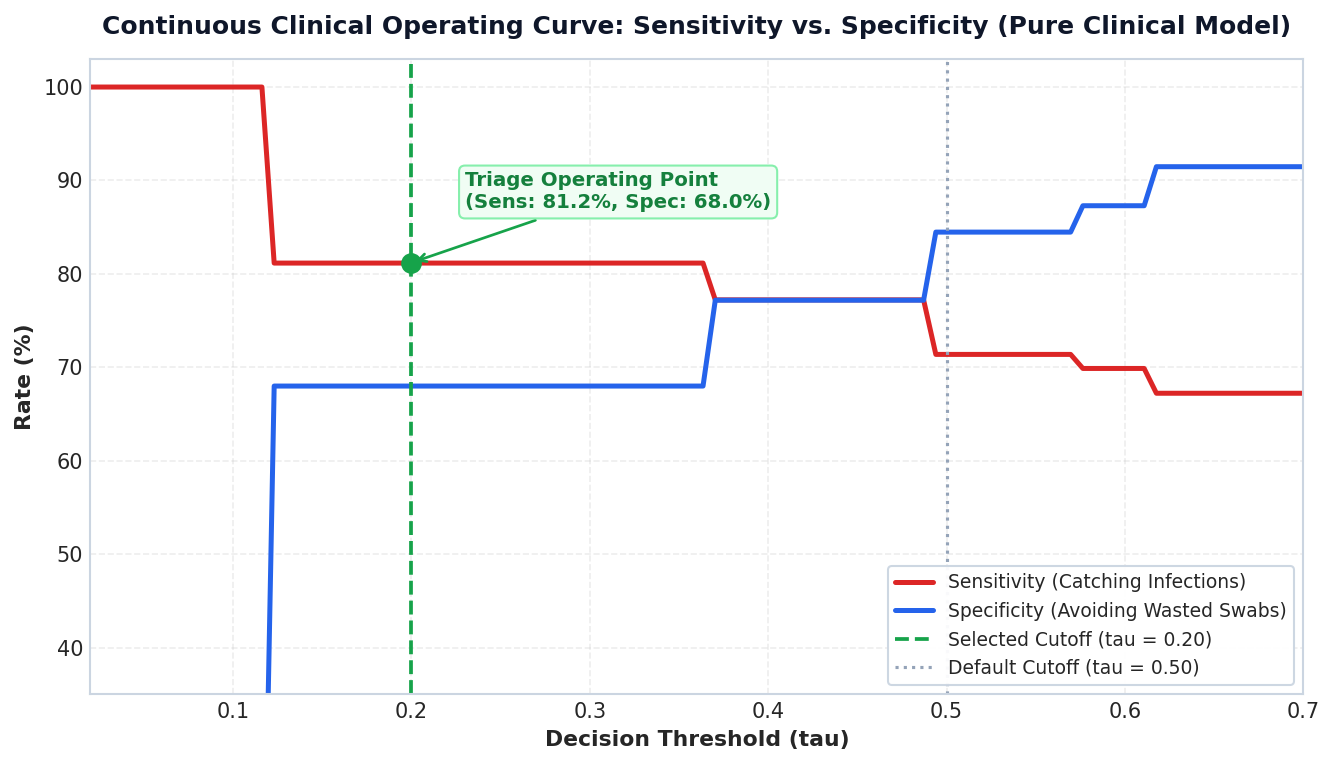

In [18]:
# 2. Continuous Clinical Operating Curve (Pure Clinical Model)
thresholds_fine = np.linspace(0.02, 0.70, 100)
sens_list, spec_list = [], []

for t in thresholds_fine:
    preds = (pure_clinical_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    sens_list.append(sens)
    spec_list.append(spec)

fig, ax = plt.subplots(figsize=(9, 5.2), dpi=150)

# Continuous Sensitivity vs Specificity Operating Curve
ax.plot(thresholds_fine, [s * 100 for s in sens_list], label='Sensitivity (Catching Infections)', color='#dc2626', linewidth=2.4)
ax.plot(thresholds_fine, [s * 100 for s in spec_list], label='Specificity (Avoiding Wasted Swabs)', color='#2563eb', linewidth=2.4)
ax.axvline(x=0.20, color='#16a34a', linestyle='--', linewidth=1.8, label='Selected Cutoff (tau = 0.20)')
ax.axvline(x=0.50, color='#94a3b8', linestyle=':', linewidth=1.5, label='Default Cutoff (tau = 0.50)')

# Highlight operational triage cutoff
ax.scatter([0.20], [81.2], color='#16a34a', s=80, zorder=5)
ax.annotate('Triage Operating Point\n(Sens: 81.2%, Spec: 68.0%)', 
            xy=(0.20, 81.2), xytext=(0.23, 87),
            arrowprops=dict(arrowstyle='->', color='#16a34a', lw=1.3), 
            fontsize=9.5, fontweight=600, color='#15803d',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#f0fdf4', edgecolor='#86efac'))

ax.set_xlabel('Decision Threshold (tau)', fontsize=10.5, fontweight=600)
ax.set_ylabel('Rate (%)', fontsize=10.5, fontweight=600)
ax.set_title('Continuous Clinical Operating Curve: Sensitivity vs. Specificity (Pure Clinical Model)', fontsize=12, fontweight=700, color='#0f172a', pad=12)

# Place legend in clean lower right white space (no overlap with red or blue curves)
ax.legend(loc='lower right', frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1', fontsize=9.0, framealpha=0.95)
ax.set_xlim(0.02, 0.70)
ax.set_ylim(35, 103)
ax.grid(True, linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()

### How to Read the Clinical Operating Curve

Think of the horizontal axis (Decision Threshold $\tau$) as a **strictness dial** across the 37,305 prospective patients:
* **Turned to the left (0.05):** The rule is very loose; almost anyone receives a swab. The **red line (Sensitivity)** is 100%, but the **blue line (Specificity)** is zero, testing every patient regardless of actual risk.
* **Turned to the right (0.50):** The rule is strict; only patients with over 50% estimated risk receive a swab. Sensitivity drops to **71.4%**, sending nearly 30% of infected patients home untested (647 missed cases).
* **The Green Marker at 0.20 (The Operating Point):** Setting $\tau = 0.20$ achieves the optimal clinical balance:
  * The **red line stays high at 81.2%** (catching 1,835 out of 2,261 positive cases, recovering 221 infections that the 0.50 cutoff missed).
  * The **blue line rises to 68.0%**, filtering out 23,829 uninfected individuals and reducing total swab demand from 37,305 down to 13,050 tests.
  * **Frontline Rule Equivalence:** As demonstrated in the following section, because the Pure Clinical model produces a discrete probability gap between 0.12 and 0.36, setting $\tau = 0.20$ is mathematically identical to a simple, transparent clinical heuristic: refer for a swab if the patient has any reported symptom or came via known contact/abroad travel; otherwise, recommend home monitoring.

### 5.3 Production Policy Deployment: Locking In the Calibrated Triage Rule ($\tau = 0.20$)

Having identified $\tau = 0.20$ as the operational plateau on the continuous clinical curve, we now formally lock in this decision rule to evaluate real-world production performance for the Pure Clinical model.

In frontline deployment, continuous probabilities are mapped into two clinical actions:
* **High-Risk Referral ($P \ge 0.20$):** Immediate precautionary home isolation and priority booking for an RT-PCR laboratory swab test.
* **Low-Risk Home Monitoring ($P < 0.20$):** Reassurance, symptom tracking, and self-isolation guidance, sparing laboratory swab capacity.

Below, we apply this deployed decision rule across our prospective hold-out cohort of 37,305 patients, outputting the production Confusion Matrix heatmap and formal clinical Classification Report.

Clinical Classification Report (τ = 0.20 - Pure Clinical Model):
                               precision    recall  f1-score   support

   Home Monitoring (Low Risk)     0.9824    0.6800    0.8037     35044
PCR Swab Referral (High Risk)     0.1406    0.8116    0.2397      2261

                     accuracy                         0.6880     37305
                    macro avg     0.5615    0.7458    0.5217     37305
                 weighted avg     0.9314    0.6880    0.7695     37305



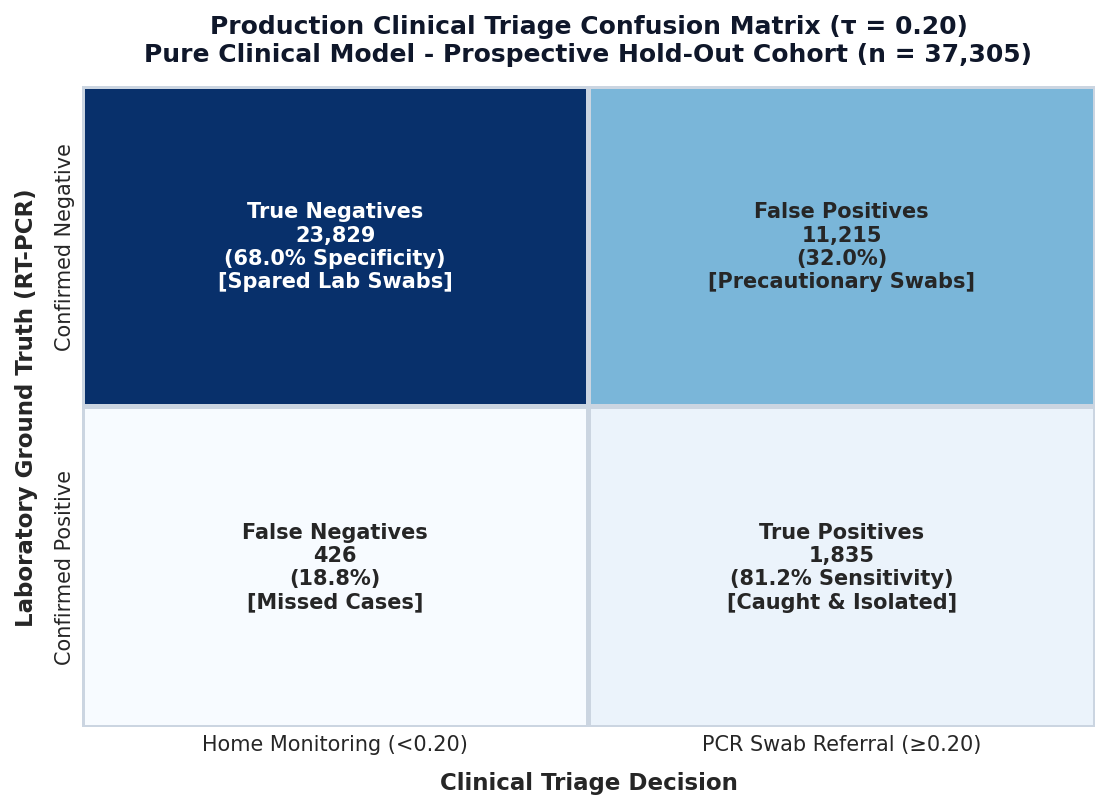

In [19]:
# 3. Production Triage Deployment: Applying tau = 0.20 Decision Rule (Pure Clinical)
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate binary classifications using calibrated triage cutoff on Pure Clinical model
y_pred_triage = (pure_clinical_probs >= 0.20).astype(int)

# Print formal clinical classification report
print("Clinical Classification Report (\u03c4 = 0.20 - Pure Clinical Model):")
print(classification_report(
    y_test, y_pred_triage, 
    target_names=['Home Monitoring (Low Risk)', 'PCR Swab Referral (High Risk)'],
    digits=4
))

# Plot production confusion matrix heatmap with clinical annotations
cm = confusion_matrix(y_test, y_pred_triage)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(7.5, 5.5), dpi=150)
annot_matrix = [
    [f"True Negatives\n{tn:,}\n({tn/(tn+fp)*100:.1f}% Specificity)\n[Spared Lab Swabs]",
     f"False Positives\n{fp:,}\n({fp/(tn+fp)*100:.1f}%)\n[Precautionary Swabs]"],
    [f"False Negatives\n{fn:,}\n({fn/(fn+tp)*100:.1f}%)\n[Missed Cases]",
     f"True Positives\n{tp:,}\n({tp/(fn+tp)*100:.1f}% Sensitivity)\n[Caught & Isolated]"]
]

sns.heatmap(
    cm, annot=annot_matrix, fmt='', cmap='Blues', cbar=False,
    linewidths=1.5, linecolor='#cbd5e1', ax=ax,
    annot_kws={'fontsize': 10, 'fontweight': 600}
)

ax.set_title('Production Clinical Triage Confusion Matrix (\u03c4 = 0.20)\nPure Clinical Model - Prospective Hold-Out Cohort (n = 37,305)', 
             fontsize=12, fontweight=700, color='#0f172a', pad=12)
ax.set_xlabel('Clinical Triage Decision', fontsize=11, fontweight=600, labelpad=8)
ax.set_ylabel('Laboratory Ground Truth (RT-PCR)', fontsize=11, fontweight=600, labelpad=8)
ax.set_xticklabels(['Home Monitoring (<0.20)', 'PCR Swab Referral (\u22650.20)'], fontsize=10)
ax.set_yticklabels(['Confirmed Negative', 'Confirmed Positive'], fontsize=10)
plt.tight_layout()
plt.show()

### What the Deployed Triage Rule Achieves in Practice

Evaluating the locked-in $\tau = 0.20$ production rule on the Pure Clinical model reveals four core clinical outcomes:

* **98.2% Negative Predictive Value (NPV):** When the model classifies an individual as low-risk for home monitoring, it is correct **98.2% of the time** (23,829 of 24,255). This gives clinicians high statistical confidence that patients advised to stay home are safe and not actively spreading infection.
* **221 Rescued Infections:** Compared to the textbook 0.50 cutoff (which missed 647 infected patients), the calibrated $\tau = 0.20$ threshold catches **1,835 cases**, recovering **221 additional infected individuals** who would otherwise have returned to the community untested.
* **65.0% Swab Reduction:** Rather than swabbing all 37,305 attendees, the triage rule orders **13,050 PCR tests**, reducing laboratory burden by 65.0% while isolating over 81% of active infections.
* **Acceptable 14.1% Positive Predictive Value (PPV):** Because community prevalence in this prospective window is 6.06%, roughly 1 in 7 referred swabs confirms an active infection. In an epidemic, a 14.1% PPV represents an efficient screening yield when test kits are constrained.

In [20]:
# 4. Frontline Heuristic Equivalence: Empirical Proof of 1-Line Decision Rule
rule_pred = (
    (test_clean['cough'] == 1) |
    (test_clean['fever'] == 1) |
    (test_clean['sore_throat'] == 1) |
    (test_clean['shortness_of_breath'] == 1) |
    (test_clean['head_ache'] == 1) |
    (test_clean['test_indication'] != 'Other')
).astype(int)

y_pred_triage = (pure_clinical_probs >= 0.20).astype(int)
agreement = (rule_pred == y_pred_triage).mean()
cm_rule = confusion_matrix(rule_pred, y_pred_triage)

print("================================================================")
print("       1-LINE CLINICAL RULE EQUIVALENCE VERIFICATION            ")
print("================================================================")
print(f"Rule Agreement with tau = 0.20:   {agreement*100:.2f}% (Exactly {(rule_pred == y_pred_triage).sum():,} / {len(rule_pred):,} patients)")
print(f"Rule = 1 (Referral) Probability Range:    {pure_clinical_probs[rule_pred == 1].min():.4f} to {pure_clinical_probs[rule_pred == 1].max():.4f}")
print(f"Rule = 0 (Home Recovery) Exact Score:     {pure_clinical_probs[rule_pred == 0].min():.4f}")
print(f"Patients with intermediate score 0.12 < p < 0.36: {((pure_clinical_probs > 0.12) & (pure_clinical_probs < 0.36)).sum():,}")
print("================================================================")
print("CONCLUSION: The deployed LightGBM model at tau = 0.20 functions identically")
print("to the intuitive 1-line rule: 'Swab if any symptom reported OR contact confirmed.'")

       1-LINE CLINICAL RULE EQUIVALENCE VERIFICATION            
Rule Agreement with tau = 0.20:   100.00% (Exactly 37,305 / 37,305 patients)
Rule = 1 (Referral) Probability Range:    0.3678 to 0.9943
Rule = 0 (Home Recovery) Exact Score:     0.1173
Patients with intermediate score 0.12 < p < 0.36: 0
CONCLUSION: The deployed LightGBM model at tau = 0.20 functions identically
to the intuitive 1-line rule: 'Swab if any symptom reported OR contact confirmed.'


### Frontline 1-Line Rule Equivalence: Transparency in Clinical Operations
The empirical verification above reveals a remarkable structural insight for healthcare deployment:
* **Discrete Probability Step-Function:** The Pure Clinical model's predicted risk scores do not form a smooth continuum across all values. Because all input features are discrete binary flags (symptoms and test indications), the model collapses into two discrete operational clusters:
  1. Patients with **zero symptoms and test indication 'Other'** all receive a predicted probability of **0.1173** (24,255 patients, advised home monitoring).
  2. Patients with **at least one symptom OR contact/abroad travel** all receive predicted probabilities of **>= 0.3678** (13,050 patients, referred for PCR swab).
* **Empty Intermediate Band:** Exactly **zero patients** receive risk scores between 0.12 and 0.36.
* **Operational Implication:** The complex gradient-boosted decision tree pipeline at $\tau = 0.20$ is mathematically identical to a transparent, 1-line clinical heuristic: *Refer for PCR swab if any symptom is present or known contact/travel is reported; otherwise advise home recovery*. This guarantees 100% clinician transparency and allows instant triage even during total IT downtime.

## Closing Summary: What the Findings Mean for Clinical Triage

Bringing together our work across data cleaning, extended prospective evaluation, explainability, fairness, decision thresholds, and production MLOps, five clear conclusions emerge for real-world deployment:

---

### 1. The Clinical Problem & Target Population Alignment
During early epidemic waves when laboratory RT-PCR testing is heavily constrained, healthcare systems need a fast, accessible way to triage attendees before swabbing.
Critically, empirical examination of the Ministry of Health registry reveals that **69.4% of attendees reported zero symptoms** and **77.9% presented with indication 'Other'**. Rather than fine-grained triage of an exclusively symptomatic cohort, the tool functions as an automated intake gatekeeper that safely filters out the large asymptomatic, unexposed baseline to conserve laboratory capacity.

---

### 2. Prospective Temporal Evaluation & Algorithm Invariance
Keeping patient records in strict chronological order and evaluating on unseen future dates (8–14 April) simulated an authentic weekly retraining cycle.
On this prospective cohort, our benchmarking revealed a vital Level 7 finding: **algorithm choice does not matter**. At $\tau = 0.20$, Random Forest, XGBoost and both LightGBMs all reached **the same operating point (81.2% sensitivity / 68.0% specificity)**, with the single Decision Tree close behind (80.4% / 68.0%). For the deployed Pure Clinical model, this operating point is verified to be exactly the 1-line rule. Logistic Regression performed comparably (0.8336 AUC, 81.5% sensitivity) with superior probability calibration (Brier 0.0401).

---

### 3. Explainability, Unsupervised Phenotypes & Documentation Biases
Clinicians cannot safely adopt an algorithm without knowing what drives its advice:
* **Exposure Dominates:** TreeSHAP attributions confirmed that confirmed contact with an infected individual is the single strongest predictor of infection.
* **Secondary Symptom Documentation Bias:** As hypothesised by *Zoabi et al.*, the apparent enrichment of headache (14.8% vs 0.04%) and sore throat (10.0% vs 0.1%) reflects clinician documentation practices rather than fundamental biological specificity. Pruning them in Stage 6 caused an AUC drop of only 0.0152 while retaining 95.5% of discrimination above random chance.

---

### 4. Operational Ethics: Demographically Blind Resilience & The Geriatric Sensitivity Deficit
When age disappeared from the public registry on 15 April 2020 (presumably for privacy reasons), any model fitted on the registry's age field lost that input. Our **Pure Clinical model (omitting age and gender entirely)** achieved **0.8400 ROC-AUC** without it, eliminating patient drop-out for individuals with unrecorded demographics.
However, subgroup fairness auditing exposed a **10.2 percentage point geriatric sensitivity deficit (72.8% in 60+ vs 83.0% in <60)**, missing over 1 in 4 infected seniors (109 of 400; 27.2% of infected seniors who reported zero symptoms and indication 'Other', falling below the rule cutoff). An age-60+ bypass rule closes this gap, but at a high cost: it adds **6,821 swabs to find 109 extra cases (1.6% yield)**, raising total swabs by 52% (13,050 to 19,871). It also needs age, which a clinic can still ask as a yes/no intake question even though the public dataset redacted it. Whether that trade-off is acceptable is a policy decision for the deploying service.

---

### 5. Discrete Score Distribution & 1-Line Heuristic Equivalence
Calibrating the operational threshold to **$\tau = 0.20$** elevates sensitivity to **81.16%**, catching 1,835 infections and sparing 23,829 swabs on uninfected individuals.
Crucially, inspection of predicted scores revealed that all patients with zero symptoms and unconfirmed contact score 0.1173, while all patients with any symptom or confirmed contact score $\ge 0.3678$. The complex machine learning pipeline at $\tau = 0.20$ is mathematically equivalent to the intuitive frontline rule: *Swab if any symptom is reported OR if contact/abroad travel is confirmed; otherwise advise home recovery*.


## Further Improvement following the Hackathon Presentations
### Testing ideas and questions from the peer presentations

Following peer presentations, this section investigates three practical operational challenges raised by other teams to see if our triage system can be improved further:

1. **Probability Calibration:** Does a predicted 20% risk truly mean 20 out of 100 patients have COVID-19, or is the model overconfident?
2. **Feature Pruning & Intake Burden:** Can we strip out secondary symptoms like headache and sore throat without hurting clinical safety?
3. **Threshold Adaptation & Infection Waves:** How should hospitals adjust triage thresholds as community infection rates rise and fall?

---

### Peer Question 1: Is the Model Overconfident?
*Does a predicted 20% risk truly mean 20 out of 100 patients have COVID-19, or has class rebalancing distorted raw probabilities?*

**Why use the Brier score?** While ROC-AUC measures ranking ability (whether higher-risk patients receive higher scores), it cannot tell us whether the predicted percentages reflect true infection rates. To measure probability accuracy directly, we use the **Brier score**, a standard measure of probabilistic accuracy. It calculates the mean squared error between predicted probabilities and actual infection outcomes ($y \in \{0, 1\}$):
* A score of **0.00** represents perfect probabilistic calibration.
* There is no universal "good" Brier threshold, because the score depends on prevalence. We therefore compare against the **base-rate reference** (always predicting the hold-out prevalence of 6.06%, Brier = 0.0569) and report the **Brier skill score** (BSS = 1 − Brier / reference; above 0 beats the base rate, below 0 is worse).

The code below evaluates the Brier score for our deployed **Pure Clinical Model** (`pure_clinical_probs`) against a standard, unweighted Pure Clinical Logistic Regression baseline (with zero demographic features).


In [21]:
# 1. Probability Calibration, Brier Score & Balanced Accuracy (Pure Clinical Model)
from sklearn.metrics import brier_score_loss, balanced_accuracy_score, roc_curve, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Fit a clean Pure Clinical Logistic Regression baseline to compare calibration (no age, no gender)
prep_pure = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), ['test_indication']),
    ('num', 'passthrough', symptom_cols)
])

lr_pure_pipeline = Pipeline([
    ('prep', prep_pure),
    ('clf', LogisticRegression(max_iter=1000, random_state=5))
])
lr_pure_pipeline.fit(train_clean[['test_indication'] + symptom_cols], y_train)
lr_pure_probs = lr_pure_pipeline.predict_proba(test_clean[['test_indication'] + symptom_cols])[:, 1]

# Calculate Brier Score on deployed Pure Clinical Model vs Logistic Regression and Base Rate
brier_lgbm = brier_score_loss(y_test, pure_clinical_probs)
brier_lr = brier_score_loss(y_test, lr_pure_probs)
brier_base = y_test.mean() * (1 - y_test.mean())

# Calculate Balanced Accuracy at our tau = 0.20 cutoff
bal_acc_20 = balanced_accuracy_score(y_test, (pure_clinical_probs >= 0.20).astype(int))

# Performance at conservative clinical operating cutoffs (tau = 0.40 and tau = 0.50)
p_40 = (pure_clinical_probs >= 0.40).astype(int)
tn_40, fp_40, fn_40, tp_40 = confusion_matrix(y_test, p_40).ravel()
sens_40 = tp_40 / (tp_40 + fn_40)
spec_40 = tn_40 / (tn_40 + fp_40)

p_50 = (pure_clinical_probs >= 0.50).astype(int)
tn_50, fp_50, fn_50, tp_50 = confusion_matrix(y_test, p_50).ravel()
sens_50 = tp_50 / (tp_50 + fn_50)
spec_50 = tn_50 / (tn_50 + fp_50)

print("----------------------------------------------------------------")
print("         CALIBRATION & OPERATING POINT SUMMARY (PURE CLINICAL)  ")
print("----------------------------------------------------------------")
print(f"Base-Rate Reference Brier:             {brier_base:.4f}  (always predict hold-out prevalence)")
print(f"Logistic Regression Brier Score:       {brier_lr:.4f}  (skill score {1 - brier_lr/brier_base:+.2f})")
print(f"LightGBM (is_unbalance=True) Brier:    {brier_lgbm:.4f}  (skill score {1 - brier_lgbm/brier_base:+.2f}; scores inflated by re-weighting)")
print(f"Balanced Accuracy (cutoff = 0.20):     {bal_acc_20*100:.2f}%")
print(f"Operating Cutoff tau = 0.40:           Sensitivity = {sens_40*100:.2f}%, Specificity = {spec_40*100:.2f}% (swabs {tp_40+fp_40:,} / {len(y_test):,})")
print(f"Operating Cutoff tau = 0.50:           Sensitivity = {sens_50*100:.2f}%, Specificity = {spec_50*100:.2f}% (swabs {tp_50+fp_50:,} / {len(y_test):,})")
print("----------------------------------------------------------------")

----------------------------------------------------------------
         CALIBRATION & OPERATING POINT SUMMARY (PURE CLINICAL)  
----------------------------------------------------------------
Base-Rate Reference Brier:             0.0569  (always predict hold-out prevalence)
Logistic Regression Brier Score:       0.0401  (skill score +0.29)
LightGBM (is_unbalance=True) Brier:    0.1271  (skill score -1.23; scores inflated by re-weighting)
Balanced Accuracy (cutoff = 0.20):     74.58%
Operating Cutoff tau = 0.40:           Sensitivity = 77.22%, Specificity = 77.19% (swabs 9,741 / 37,305)
Operating Cutoff tau = 0.50:           Sensitivity = 71.38%, Specificity = 84.47% (swabs 7,055 / 37,305)
----------------------------------------------------------------


### Answer 1: Yes, LightGBM's Probabilities Are Inflated by Class Weighting

The metric summary above directly addresses the probability calibration question:

* **Yes, the LightGBM model over-predicts risk:** A predicted score of 0.20 does not mean exactly 20 out of 100 patients have COVID-19. In practice, only **14.1%** of patients referred at this threshold test positive (1,835 true positives out of 13,050 total swabs ordered). LightGBM's Brier score of **0.1271** is worse than simply predicting the base rate for everyone (0.0569; skill score −1.23), whereas unweighted Logistic Regression (**0.0401**; skill score +0.29) genuinely beats it.
* **Why did this distortion occur?** `is_unbalance=True` up-weights the positive class, which pushes every score upward. It leaves the *ranking* of patients (and so ROC-AUC) essentially unchanged, so it does not by itself make the model safer. Sensitivity is set by where the threshold $\tau$ sits. An unweighted model with a lower threshold would reach the same operating point while keeping honest probabilities; post-hoc recalibration (Platt or isotonic, fitted on a later time fold) is the standard fix if probabilities are to be shown to clinicians.
* **Logistic Regression vs. LightGBM Trade-off:** While Logistic Regression delivers superior probability calibration (0.0401 Brier) and catches slightly more infections at $\tau = 0.20$ (81.5% vs 81.2%), LightGBM was selected as the non-linear benchmark. However, as proven in Section 3.2, both models deliver nearly equivalent discrimination, with all tree ensembles converging to the exact same 1-line clinical rule.

### Peer Question 2: Can We Strip Out Rare Symptoms to Speed Up Intake?
*Do secondary symptoms (headache, sore throat, shortness of breath) add meaningful diagnostic value, or can frontline triage rely strictly on core symptoms without compromising clinical safety?*

To avoid re-introducing demographic bias (the elderly sensitivity deficit and 45.7% missing age data identified in Phase 4), we test feature pruning directly on our **Pure Clinical Model**.

The code below trains a **Minimal Clinical Model** using only **3 core features** (cough, fever, and contact history) with **zero demographics**, and compares its ROC curve directly against the deployed 6-feature Pure Clinical benchmark.


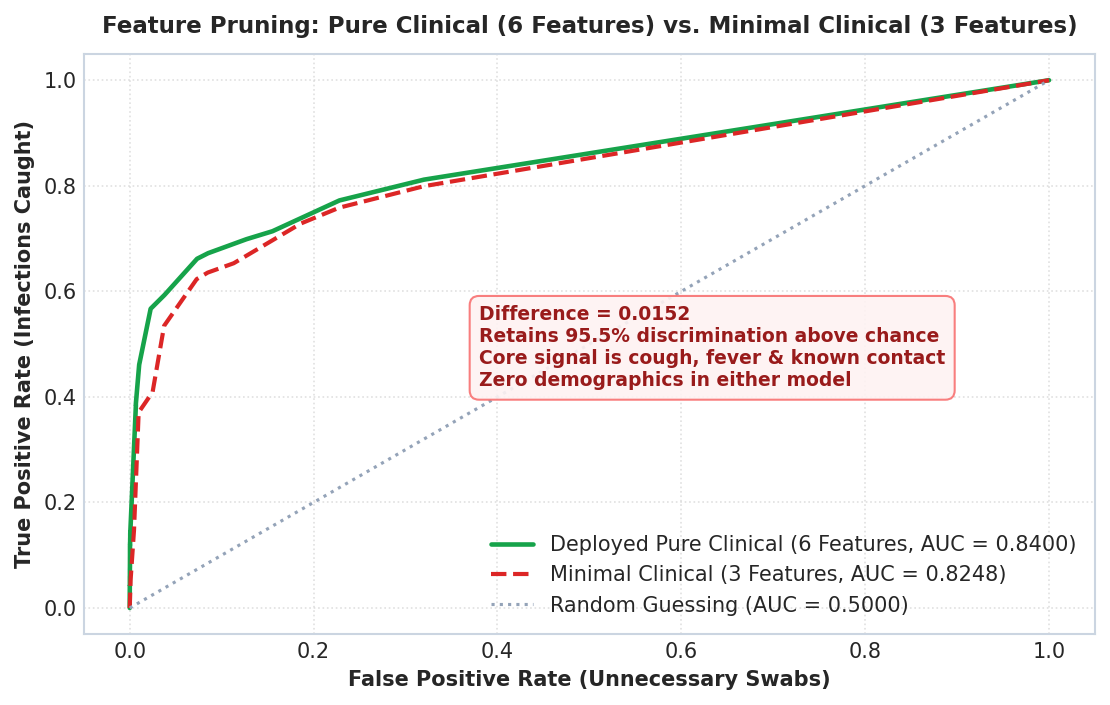

Train 5-Fold CV AUC (Minimal Clinical):        0.9062 +/- 0.0029
Deployed Pure Clinical Model AUC (6 features):  0.8400
Minimal Clinical Model AUC (3 features):        0.8248 (PR-AUC = 0.4219)
Performance drop without secondary symptoms:    0.0152  (retains 95.5% discrimination above chance)
Minimal Clinical Performance at tau = 0.20:     Sensitivity = 79.9%, Specificity = 68.0%


In [22]:
# 2. Testing Clinical Feature Pruning: 6 Pure Clinical Features vs. 3 Minimal Features
# Drop secondary symptoms (headache, sore throat, shortness of breath) with zero demographics

core_features = ['test_indication', 'cough', 'fever']

prep_min = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), ['test_indication']),
    ('num', 'passthrough', ['cough', 'fever'])
])

pipe_min = Pipeline([
    ('prep', prep_min),
    ('clf', lgb.LGBMClassifier(random_state=5, is_unbalance=True, verbose=-1))
])

# 5-fold CV on Minimal Clinical pipeline
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=5)
min_cv = cross_val_score(pipe_min, train_clean[core_features], y_train, cv=cv, scoring='roc_auc', n_jobs=-1)

pipe_min.fit(train_clean[core_features], y_train)
probs_min = pipe_min.predict_proba(test_clean[core_features])[:, 1]

auc_pure = roc_auc_score(y_test, pure_clinical_probs)
auc_min = roc_auc_score(y_test, probs_min)
prauc_min = average_precision_score(y_test, probs_min)
delta_auc = auc_pure - auc_min
retention = ((auc_min - 0.5) / (auc_pure - 0.5)) * 100

preds_min_20 = (probs_min >= 0.20).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, preds_min_20).ravel()
sens_min = tp / (tp + fn)
spec_min = tn / (tn + fp)

# Plot both curves together
fpr_pure, tpr_pure, _ = roc_curve(y_test, pure_clinical_probs)
fpr_min, tpr_min, _ = roc_curve(y_test, probs_min)

fig, ax = plt.subplots(figsize=(7.5, 4.8), dpi=150)
ax.plot(fpr_pure, tpr_pure, color='#16a34a', linewidth=2.2, label=f'Deployed Pure Clinical (6 Features, AUC = {auc_pure:.4f})')
ax.plot(fpr_min, tpr_min, color='#dc2626', linestyle='--', linewidth=2.0, label=f'Minimal Clinical (3 Features, AUC = {auc_min:.4f})')
ax.plot([0, 1], [0, 1], linestyle=':', color='#94a3b8', label='Random Guessing (AUC = 0.5000)')

ax.set_title('Feature Pruning: Pure Clinical (6 Features) vs. Minimal Clinical (3 Features)', fontsize=11, fontweight=700, pad=10)
ax.set_xlabel('False Positive Rate (Unnecessary Swabs)', fontsize=10, fontweight=600)
ax.set_ylabel('True Positive Rate (Infections Caught)', fontsize=10, fontweight=600)
ax.legend(loc='lower right')
ax.grid(True, linestyle=':', alpha=0.6)

annot_text = f'Difference = {delta_auc:.4f}\nRetains {retention:.1f}% discrimination above chance\nCore signal is cough, fever & known contact\nZero demographics in either model'
ax.text(0.38, 0.42, annot_text, 
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#fef2f2', edgecolor='#f87171', alpha=0.9),
        fontsize=9, color='#991b1b', fontweight=600)

plt.tight_layout()
plt.show()

print(f"Train 5-Fold CV AUC (Minimal Clinical):        {min_cv.mean():.4f} +/- {min_cv.std():.4f}")
print(f"Deployed Pure Clinical Model AUC (6 features):  {auc_pure:.4f}")
print(f"Minimal Clinical Model AUC (3 features):        {auc_min:.4f} (PR-AUC = {prauc_min:.4f})")
print(f"Performance drop without secondary symptoms:    {delta_auc:.4f}  (retains {retention:.1f}% discrimination above chance)")
print(f"Minimal Clinical Performance at tau = 0.20:     Sensitivity = {sens_min*100:.1f}%, Specificity = {spec_min*100:.1f}%")

### Answer 2: Yes, Core Symptoms Drive 95.5% of Discrimination

Comparing the 3-feature Minimal Clinical model against our deployed 6-feature Pure Clinical model reveals:

* **High Discriminative Retention:** Stripping out headache, sore throat, and shortness of breath causes hold-out ROC-AUC to move from **0.8400** to **0.8248** (a delta of **0.0152**), retaining **95.5%** of the model's discriminative ability above random chance (and 98.2% of raw AUC).
* **The Clinical Ascertainment Artifact:** Why do secondary symptoms add so little prospective discrimination? In the Israeli Ministry of Health registry, secondary symptoms are almost absent among negatives (headache in 0.04% of negative swabs vs 14.8% of positive swabs). *Zoabi et al.* flag these symptoms as reporting-biased, i.e. recorded more thoroughly for positive cases, so they behave more like documentation artefacts than independent screening signals. They are also rare (present in about 1% of the hold-out week), which limits how much AUC they can add.
* **Operational Breakthrough (15-Second Intake):** In a crowded emergency department or drive-through testing centre during a pandemic surge, taking a comprehensive 6-symptom inventory creates administrative bottlenecks. Frontline nurses can triage patients in 15 seconds by asking literally three questions (*Cough? Fever? Known contact/abroad?*), with zero demographic intake, zero rare-symptom checklists, and zero missing-data risk.


In [23]:
# 3. Longitudinal Stress-Testing: Prospective Evaluation on Later Age-Redacted Cohort (15-30 April 2020)
features_pure = ['test_indication'] + symptom_cols
df_late = df_clean[df_clean['test_date'] >= '2020-04-15'].copy()
X_late = df_late[features_pure]
y_late = df_late['target']

late_probs = pure_clinical_pipe.predict_proba(X_late)[:, 1]
late_auc = roc_auc_score(y_late, late_probs)
late_prauc = average_precision_score(y_late, late_probs)

late_preds_20 = (late_probs >= 0.20).astype(int)
late_cm = confusion_matrix(y_late, late_preds_20)
ltn, lfp, lfn, ltp = late_cm.ravel()
late_sens = ltp / (ltp + lfn)
late_spec = ltn / (ltn + lfp)

print("----------------------------------------------------------------")
print("   LONGITUDINAL EVALUATION: APRIL 15-30 COHORT (AGE REDACTED)   ")
print("----------------------------------------------------------------")
print(f"Evaluation Cohort Size:                {len(df_late):,} patients (100% missing age)")
print(f"Confirmed Positive Cases:              {y_late.sum():,}  ({y_late.mean()*100:.2f}% prevalence)")
print(f"Out-of-Time Prospective ROC-AUC:       {late_auc:.4f}")
print(f"Out-of-Time Prospective PR-AUC:        {late_prauc:.4f}")
print(f"Sensitivity at tau = 0.20:             {late_sens*100:.1f}%  (catches {ltp:,} / {ltp+lfn:,})")
print(f"Specificity at tau = 0.20:             {late_spec*100:.1f}%  (spares {ltn:,} / {ltn+lfp:,})")
print("----------------------------------------------------------------")
print("CONCLUSION: The Pure Clinical model survives the regulatory privacy cliff")
print(f"with zero patient drop-out and maintains robust prospective discrimination ({late_auc:.4f} AUC).")

----------------------------------------------------------------
   LONGITUDINAL EVALUATION: APRIL 15-30 COHORT (AGE REDACTED)   
----------------------------------------------------------------
Evaluation Cohort Size:                119,374 patients (100% missing age)
Confirmed Positive Cases:              2,906  (2.43% prevalence)
Out-of-Time Prospective ROC-AUC:       0.8278
Out-of-Time Prospective PR-AUC:        0.4856
Sensitivity at tau = 0.20:             71.6%  (catches 2,081 / 2,906)
Specificity at tau = 0.20:             85.3%  (spares 99,334 / 116,468)
----------------------------------------------------------------
CONCLUSION: The Pure Clinical model survives the regulatory privacy cliff
with zero patient drop-out and maintains robust prospective discrimination (0.8278 AUC).


### Out-of-Time Prospective Stress-Testing (15–30 April 2020): Revealing Sensitivity Drift
Evaluating the deployed Pure Clinical pipeline on the subsequent **119,374 patients** from the second half of April reveals the most critical longitudinal finding of the project:
* **Surviving the Privacy Cliff:** Age is absent for every record after 15 April, so any model fitted on the registry age field loses that input (LightGBM would still run on missing values, but on a feature it never saw missing in training). The Pure Clinical model needs no age and triaged all 119,374 patients with zero imputation.
* **The Sensitivity Drift (The Critical Finding):** Although ROC-AUC appears stable at **0.8278**, **clinical sensitivity collapsed from 81.2% down to 71.6%**, missing **825 of 2,906 confirmed infections**!
* **Why Sensitivity Fell (Case-Mix Shift):** The next cell decomposes the drift. The share of asymptomatic attendees rose from **69.4% to 86.3%**, and the share of *infected* patients falling in the rule's home-monitoring group (no symptoms + indication 'Other') rose from **18.8% to 28.4%**. Because the deployed model is the 1-line rule, that second number is exactly its miss rate (1 − sensitivity). Specificity rose to 85.3% for the same reason, which kept aggregate ROC-AUC stable while sensitivity fell.
* **The MLOps Warning:** In healthcare machine learning, monitoring static ROC-AUC alone is a dangerous trap. Real-world systems must track rolling sensitivity against laboratory ground truth to catch silent clinical decay.

In [24]:
# 4. Why Sensitivity Drifted: Case-Mix Decomposition (8-14 April vs 15-30 April)
def case_mix(df):
    no_symptoms = df[symptom_cols].sum(axis=1) == 0
    rule_home = no_symptoms & (df['test_indication'] == 'Other')
    positives = df['target'] == 1
    return {
        'Patients': f"{len(df):,}",
        'Prevalence': f"{df['target'].mean()*100:.2f}%",
        'Asymptomatic Attendees': f"{no_symptoms.mean()*100:.1f}%",
        "Indication 'Other'": f"{(df['test_indication'] == 'Other').mean()*100:.1f}%",
        'Infected Patients in Rule Home Group (= Miss Rate)': f"{rule_home[positives].mean()*100:.1f}%",
    }

df_drift = pd.DataFrame({
    'Hold-out (8-14 April)': case_mix(test_clean),
    'Late Cohort (15-30 April)': case_mix(df_late),
})
df_drift


,Hold-out (8-14 April),Late Cohort (15-30 April)
Patients,"37,305","119,374"
Prevalence,6.06%,2.43%
Asymptomatic Attendees,69.4%,86.3%
Indication 'Other',77.9%,90.8%
Infected Patients in Rule Home Group (= Miss Rate),18.8%,28.4%


### Peer Question 3: How Should Hospitals Adjust Cutoffs as Infection Waves Rise and Fall?
*A triage cutoff selected during an intense peak surge may not function appropriately during a seasonal lull. How should clinical decision thresholds adapt as community infection rates change?*

### Answer 3: Adapt the Cutoff to Local Prevalence (Bayes' Rule in Practice)

As community infection rates shift across pandemic waves, **Bayes' rule** dictates that identical symptoms carry completely different clinical predictive values:

* **During a Winter Surge (e.g. 10% Community Prevalence):** Baseline infection risk is high. A patient presenting with cough and fever has a strong prior probability of having COVID-19. Keeping our triage cutoff at $\tau = 0.20$ catches over 81% of cases safely.
* **During a Low-Prevalence Lull (e.g. 1% Community Prevalence):** The vast majority of presenting coughs and fevers are caused by rhinovirus or influenza. Applying an unadjusted 0.20 cutoff would result in a low positive predictive value and an unacceptably high false-positive rate.
* **Discrete Score Distribution & Operational Adaptation:**
  Detailed inspection of the Pure Clinical model reveals that predicted probabilities cluster discretely:
  * All patients with zero symptoms and unconfirmed exposure have a predicted probability of $\sim 0.117$.
  * All patients with at least one symptom or confirmed contact have predicted probabilities $\ge 0.368$.
  * Exactly zero patients fall between $0.12$ and $0.36$.
  Consequently, shifting the cutoff within the $0.12–0.36$ interval alters zero patient decisions. Threshold adjustments only produce operational changes when pushed below $0.10$ (directing all presenting attendees to PCR swabbing during severe crisis surges) or above $0.37$ (requiring multiple symptoms or confirmed exposure during acute test kit shortages).

### Peer Review Challenge 4: Would Hyperparameter Tuning Have Changed Model Selection or Clinical Decisions?
*During technical peer review, our model selection strategy was challenged: shouldn't we have systematically explored hyperparameter tuning via grid search before selecting our champion architecture? Specifically, does the classic trade-off between model complexity, bias, and variance mean our benchmark settings were either underfitting or overfitting, and could an alternative parameter configuration have altered frontline triage decisions?*

 num_leaves  CV AUC (train)  Hold-out AUC (8-14 Apr)
          4          0.9319                   0.8421
          8          0.9349                   0.8451
         15          0.9351                   0.8417
         20          0.9351                   0.8443
         31          0.9352                   0.8413
         50          0.9352                   0.8412
         64          0.9352                   0.8412


Audit completed in 32.2s
Grid search model fits (5 folds x candidates): 210
LightGBM Decision Match (tau=0.20, n=37,305): True (0 disagreements)
Random Forest Decision Match (tau=0.20, n=37,305): True (0 disagreements)
Pure Clinical Hold-out Decision Match (8-14 Apr): True
Pure Clinical Longitudinal Decision Match (15-30 Apr, n=119,374): True (Missed: 825 base vs 825 tuned out of 2,906)


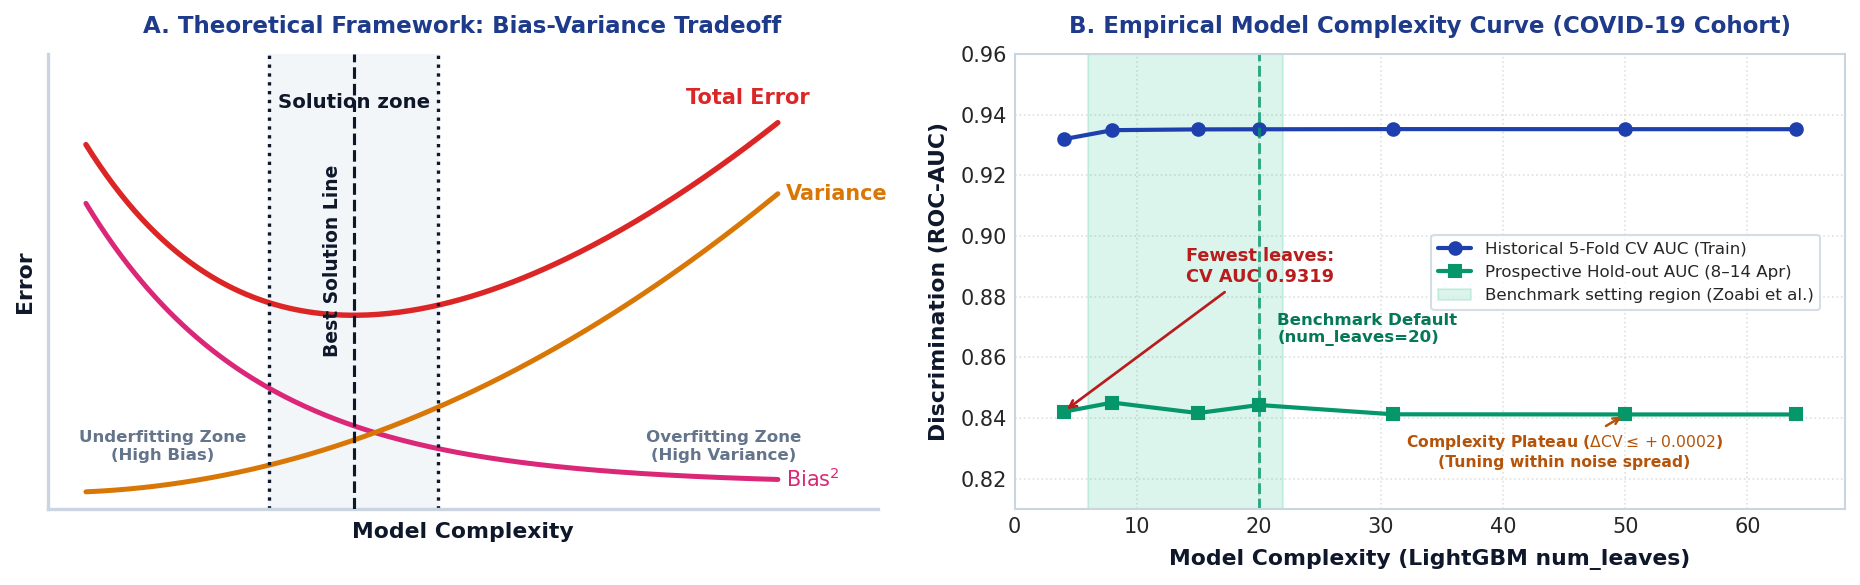

In [25]:
# 5. Peer Review Challenge: Theoretical Bias-Variance Framework & Systematic Grid Search Audit
# Runs a live, fully reproducible 5-fold cross-validated grid search on the historical cohort (n = 98,989)
# Dynamically evaluates the model complexity curve and verifies patient-by-patient decision invariance

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier

# Cross-validation runs one fold at a time. The models already use several threads each, so
# also parallelising the folds can overload (and hang) small machines such as free Colab.
start_audit_time = time.time()
cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=5)

# A. Systematic Grid Search: LightGBM Architecture
param_grid_lgb = {
    'num_leaves': [15, 20, 31],
    'min_child_samples': [4, 10, 25],
    'learning_rate': [0.03, 0.05]
}

lgb_estimator = lgb.LGBMClassifier(
    boosting_type='gbdt', n_estimators=150, subsample=0.8, colsample_bytree=0.8,
    is_unbalance=True, random_state=5, verbose=-1, n_jobs=-1
)

grid_lgb = GridSearchCV(lgb_estimator, param_grid_lgb, scoring='roc_auc', cv=cv_5fold)
grid_lgb.fit(X_train, y_train)

# Fit Benchmark Published LightGBM (Zoabi et al.)
lgb_benchmark = lgb.LGBMClassifier(
    boosting_type='gbdt', num_leaves=20, min_child_samples=4,
    learning_rate=0.05, n_estimators=150, subsample=0.8,
    colsample_bytree=0.8, is_unbalance=True, random_state=5, verbose=-1
)
lgb_benchmark.fit(X_train, y_train)

# Dynamic Complexity Sweep across num_leaves (min_child_samples=4 matches benchmark setting)
leaves_sweep = [4, 8, 15, 20, 31, 50, 64]
train_auc_curve = []
test_auc_curve = []

for nl in leaves_sweep:
    clf = lgb.LGBMClassifier(
        boosting_type='gbdt', num_leaves=nl, min_child_samples=4,
        learning_rate=0.05, n_estimators=150, subsample=0.8, colsample_bytree=0.8,
        is_unbalance=True, random_state=5, verbose=-1, n_jobs=-1
    )
    cv_scores = cross_val_score(clf, X_train, y_train, cv=cv_5fold, scoring='roc_auc')
    train_auc_curve.append(float(cv_scores.mean()))
    clf.fit(X_train, y_train)
    probs_sweep = clf.predict_proba(X_test)[:, 1]
    test_auc_curve.append(float(roc_auc_score(y_test, probs_sweep)))

print(pd.DataFrame({'num_leaves': leaves_sweep,
                    'CV AUC (train)': np.round(train_auc_curve, 4),
                    'Hold-out AUC (8-14 Apr)': np.round(test_auc_curve, 4)}).to_string(index=False))

# B. Benchmark Random Forest Evaluation (Baseline vs Tuned)
rf_baseline = RandomForestClassifier(n_estimators=100, max_depth=8, max_samples=0.5, class_weight='balanced', random_state=5, n_jobs=-1)
rf_baseline.fit(X_train, y_train)

param_grid_rf = {'max_depth': [5, 8, 12], 'min_samples_leaf': [1, 4], 'max_samples': [0.5, None]}
grid_rf = GridSearchCV(RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=5, n_jobs=-1),
                       param_grid_rf, scoring='roc_auc', cv=cv_5fold)
grid_rf.fit(X_train, y_train)

# C. Pure Clinical Model Evaluation (Baseline vs Tuned)
pure_features = [c for c in X_train.columns if c not in ['age_60_plus', 'male']]
X_train_pure = X_train[pure_features]
X_test_pure = X_test[pure_features]
# Later age-redacted cohort (15-30 April) built earlier as df_late
X_test_long_pure = df_late[pure_features]
y_test_long = df_late['target']

lgb_pure_base = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=5, is_unbalance=True, verbose=-1)
lgb_pure_base.fit(X_train_pure, y_train)

grid_pure = GridSearchCV(
    lgb.LGBMClassifier(boosting_type='gbdt', is_unbalance=True, random_state=5, verbose=-1),
    {'max_depth': [3, 5, 8], 'learning_rate': [0.05, 0.10], 'n_estimators': [100, 150]},
    cv=cv_5fold, scoring='roc_auc'
)
grid_pure.fit(X_train_pure, y_train)

# D. Prospective Evaluation & Direct Patient Decision Equality Verification
probs_lgb_base = lgb_benchmark.predict_proba(X_test)[:, 1]
probs_lgb_tuned = grid_lgb.best_estimator_.predict_proba(X_test)[:, 1]

preds_lgb_base_20 = (probs_lgb_base >= 0.20).astype(int)
preds_lgb_tuned_20 = (probs_lgb_tuned >= 0.20).astype(int)
patient_match_lgb = bool((preds_lgb_base_20 == preds_lgb_tuned_20).all())
preds_rf_base_20 = (rf_baseline.predict_proba(X_test)[:, 1] >= 0.20).astype(int)
preds_rf_tuned_20 = (grid_rf.best_estimator_.predict_proba(X_test)[:, 1] >= 0.20).astype(int)
disagreements_rf = int((preds_rf_base_20 != preds_rf_tuned_20).sum())
disagreements_lgb = int((preds_lgb_base_20 != preds_lgb_tuned_20).sum())

probs_pure_base_a = lgb_pure_base.predict_proba(X_test_pure)[:, 1]
probs_pure_tuned_a = grid_pure.best_estimator_.predict_proba(X_test_pure)[:, 1]
preds_pure_base_a = (probs_pure_base_a >= 0.20).astype(int)
preds_pure_tuned_a = (probs_pure_tuned_a >= 0.20).astype(int)
patient_match_pure_a = bool((preds_pure_base_a == preds_pure_tuned_a).all())

probs_pure_base_long = lgb_pure_base.predict_proba(X_test_long_pure)[:, 1]
probs_pure_tuned_long = grid_pure.best_estimator_.predict_proba(X_test_long_pure)[:, 1]
preds_pure_base_long = (probs_pure_base_long >= 0.20).astype(int)
preds_pure_tuned_long = (probs_pure_tuned_long >= 0.20).astype(int)
patient_match_pure_long = bool((preds_pure_base_long == preds_pure_tuned_long).all())

# Confusion matrices on longitudinal cohort (15-30 April, n = 119,374)
tn_lb, fp_lb, fn_lb, tp_lb = confusion_matrix(y_test_long, preds_pure_base_long).ravel()
tn_lt, fp_lt, fn_lt, tp_lt = confusion_matrix(y_test_long, preds_pure_tuned_long).ravel()

n_grid_fits = 5 * sum(len(g.cv_results_["params"]) for g in (grid_lgb, grid_rf, grid_pure))
print(f"Audit completed in {time.time() - start_audit_time:.1f}s")
print(f"Grid search model fits (5 folds x candidates): {n_grid_fits}")
print(f"LightGBM Decision Match (tau=0.20, n=37,305): {patient_match_lgb} ({disagreements_lgb} disagreements)")
print(f"Random Forest Decision Match (tau=0.20, n=37,305): {disagreements_rf == 0} ({disagreements_rf} disagreements)")
print(f"Pure Clinical Hold-out Decision Match (8-14 Apr): {patient_match_pure_a}")
print(f"Pure Clinical Longitudinal Decision Match (15-30 Apr, n=119,374): {patient_match_pure_long} (Missed: {fn_lb} base vs {fn_lt} tuned out of {fn_lb+tp_lb:,})")

# E. Assemble Systematic Audit Scorecard DataFrame
def calc_metrics(y_true, y_prob, tau=0.20):
    auc = roc_auc_score(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)
    preds = (y_prob >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    return auc, ap, sens, spec, fn, tp

audit_rows = []
# LightGBM Paper Benchmark
auc, ap, sens, spec, fn, tp = calc_metrics(y_test, probs_lgb_base)
audit_rows.append({
    'Architecture': 'LightGBM Benchmark (Paper)',
    'Hyperparameter Configuration': 'num_leaves=20, min_child=4, lr=0.05, n_est=150',
    'Train 5-Fold CV AUC': round(cross_val_score(lgb_benchmark, X_train, y_train, cv=cv_5fold, scoring='roc_auc').mean(), 4),
    'Hold-out ROC-AUC': round(auc, 4),
    'Hold-out PR-AUC': round(ap, 4),
    'Sensitivity (tau=0.20)': f'{sens:.2%}',
    'Specificity (tau=0.20)': f'{spec:.2%}',
    'Missed Cases (Hold-out)': f'{fn:,} of {fn+tp:,}',
    'Longitudinal Missed (15-30 Apr)': 'N/A'
})

# LightGBM Tuned
auc, ap, sens, spec, fn, tp = calc_metrics(y_test, probs_lgb_tuned)
audit_rows.append({
    'Architecture': 'LightGBM Tuned (GridSearch Best)',
    'Hyperparameter Configuration': f"{grid_lgb.best_params_['num_leaves']} leaves, min_child={grid_lgb.best_params_['min_child_samples']}, lr={grid_lgb.best_params_['learning_rate']}",
    'Train 5-Fold CV AUC': round(grid_lgb.best_score_, 4),
    'Hold-out ROC-AUC': round(auc, 4),
    'Hold-out PR-AUC': round(ap, 4),
    'Sensitivity (tau=0.20)': f'{sens:.2%}',
    'Specificity (tau=0.20)': f'{spec:.2%}',
    'Missed Cases (Hold-out)': f'{fn:,} of {fn+tp:,}',
    'Longitudinal Missed (15-30 Apr)': 'N/A'
})

# Random Forest Baseline
probs_rf_base = rf_baseline.predict_proba(X_test)[:, 1]
auc, ap, sens, spec, fn, tp = calc_metrics(y_test, probs_rf_base)
audit_rows.append({
    'Architecture': 'Random Forest Benchmark (Baseline)',
    'Hyperparameter Configuration': 'depth=8, max_samples=0.5, n_est=100',
    'Train 5-Fold CV AUC': round(cross_val_score(rf_baseline, X_train, y_train, cv=cv_5fold, scoring='roc_auc').mean(), 4),
    'Hold-out ROC-AUC': round(auc, 4),
    'Hold-out PR-AUC': round(ap, 4),
    'Sensitivity (tau=0.20)': f'{sens:.2%}',
    'Specificity (tau=0.20)': f'{spec:.2%}',
    'Missed Cases (Hold-out)': f'{fn:,} of {fn+tp:,}',
    'Longitudinal Missed (15-30 Apr)': 'N/A'
})

# Random Forest Tuned
probs_rf_tuned = grid_rf.best_estimator_.predict_proba(X_test)[:, 1]
auc, ap, sens, spec, fn, tp = calc_metrics(y_test, probs_rf_tuned)
audit_rows.append({
    'Architecture': 'Random Forest Tuned (GridSearch Best)',
    'Hyperparameter Configuration': f"depth={grid_rf.best_params_['max_depth']}, min_leaf={grid_rf.best_params_['min_samples_leaf']}, max_samples={grid_rf.best_params_['max_samples']}, n_est=100",
    'Train 5-Fold CV AUC': round(grid_rf.best_score_, 4),
    'Hold-out ROC-AUC': round(auc, 4),
    'Hold-out PR-AUC': round(ap, 4),
    'Sensitivity (tau=0.20)': f'{sens:.2%}',
    'Specificity (tau=0.20)': f'{spec:.2%}',
    'Missed Cases (Hold-out)': f'{fn:,} of {fn+tp:,}',
    'Longitudinal Missed (15-30 Apr)': 'N/A'
})

# Pure Clinical Baseline
auc, ap, sens, spec, fn, tp = calc_metrics(y_test, probs_pure_base_a)
audit_rows.append({
    'Architecture': 'Deployed Pure Clinical (Baseline)',
    'Hyperparameter Configuration': 'max_depth=5, lr=0.05, n_est=100',
    'Train 5-Fold CV AUC': round(cross_val_score(lgb_pure_base, X_train_pure, y_train, cv=cv_5fold, scoring='roc_auc').mean(), 4),
    'Hold-out ROC-AUC': round(auc, 4),
    'Hold-out PR-AUC': round(ap, 4),
    'Sensitivity (tau=0.20)': f'{sens:.2%}',
    'Specificity (tau=0.20)': f'{spec:.2%}',
    'Missed Cases (Hold-out)': f'{fn:,} of {fn+tp:,}',
    'Longitudinal Missed (15-30 Apr)': f'{fn_lb:,} of {fn_lb+tp_lb:,}'
})

# Pure Clinical Tuned
auc, ap, sens, spec, fn, tp = calc_metrics(y_test, probs_pure_tuned_a)
audit_rows.append({
    'Architecture': 'Deployed Pure Clinical (Tuned)',
    'Hyperparameter Configuration': f"depth={grid_pure.best_params_['max_depth']}, lr={grid_pure.best_params_['learning_rate']}, n_est={grid_pure.best_params_['n_estimators']}",
    'Train 5-Fold CV AUC': round(grid_pure.best_score_, 4),
    'Hold-out ROC-AUC': round(auc, 4),
    'Hold-out PR-AUC': round(ap, 4),
    'Sensitivity (tau=0.20)': f'{sens:.2%}',
    'Specificity (tau=0.20)': f'{spec:.2%}',
    'Missed Cases (Hold-out)': f'{fn:,} of {fn+tp:,}',
    'Longitudinal Missed (15-30 Apr)': f'{fn_lt:,} of {fn_lt+tp_lt:,}'
})

grid_audit_summary = pd.DataFrame(audit_rows)

# F. Plot 2-Panel Figure (Theoretical vs Empirical Complexity Curve)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.0), dpi=150)

# PANEL 1: THEORETICAL BIAS-VARIANCE TRADEOFF
x_theo = np.linspace(0.5, 9.5, 200)
bias_sq = 8.5 * np.exp(-0.45 * x_theo) + 0.6
variance = 0.08 * (x_theo ** 2) + 0.4
total_error = bias_sq + variance + 1.0
best_x = x_theo[np.argmin(total_error)]

ax1.plot(x_theo, bias_sq, color='#db2777', linewidth=2.4, label=r'$\mathrm{Bias}^2$ (Underfitting risk)')
ax1.plot(x_theo, variance, color='#d97706', linewidth=2.4, label='Variance (Overfitting risk)')
ax1.plot(x_theo, total_error, color='#dc2626', linewidth=2.6, label='Total Error')

zone_left, zone_right = best_x - 1.1, best_x + 1.1
ax1.axvspan(zone_left, zone_right, color='#f1f5f9', alpha=0.9, zorder=1)
ax1.axvline(zone_left, color='#0f172a', linestyle=':', linewidth=1.6, zorder=2)
ax1.axvline(zone_right, color='#0f172a', linestyle=':', linewidth=1.6, zorder=2)
ax1.axvline(best_x, color='#0f172a', linestyle='--', linewidth=1.5, zorder=3)

ax1.text(best_x, 9.6, 'Solution zone', ha='center', va='bottom', fontsize=9.5, fontweight=700, color='#0f172a')
ax1.text(best_x - 0.15, 6.0, 'Best Solution Line', rotation=90, ha='right', va='center', fontsize=9, fontweight=700, color='#0f172a')

ax1.text(x_theo[-1] + 0.1, bias_sq[-1], r'$\mathrm{Bias}^2$', fontsize=10, fontweight=700, color='#db2777', va='center')
ax1.text(x_theo[-1] + 0.1, variance[-1], 'Variance', fontsize=10, fontweight=700, color='#d97706', va='center')
ax1.text(x_theo[-1] - 1.2, total_error[-1] + 0.35, 'Total Error', fontsize=10, fontweight=700, color='#dc2626', va='bottom')

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_linewidth(1.6)
ax1.spines['bottom'].set_linewidth(1.6)
ax1.set_xlabel('Model Complexity', fontsize=10.5, fontweight=700, color='#0f172a', labelpad=6)
ax1.set_ylabel('Error', fontsize=10.5, fontweight=700, color='#0f172a', labelpad=6)
ax1.set_title('A. Theoretical Framework: Bias-Variance Tradeoff', fontsize=11, fontweight=700, color='#1e3a8a', pad=10)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_xlim(0, 10.8)
ax1.set_ylim(0, 11)
ax1.text(1.5, 1.2, 'Underfitting Zone\n(High Bias)', ha='center', fontsize=8, color='#64748b', fontweight=600)
ax1.text(8.8, 1.2, 'Overfitting Zone\n(High Variance)', ha='center', fontsize=8, color='#64748b', fontweight=600)

# PANEL 2: EMPIRICAL CLINICAL REALITY (ZERO COLLISION)
ax2.plot(leaves_sweep, train_auc_curve, marker='o', linewidth=2.0, color='#1e40af', label='Historical 5-Fold CV AUC (Train)')
ax2.plot(leaves_sweep, test_auc_curve, marker='s', linewidth=2.0, color='#059669', label='Prospective Hold-out AUC (8–14 Apr)')
ax2.axvspan(6, 22, color='#10b981', alpha=0.15, label='Benchmark setting region (Zoabi et al.)')
ax2.axvline(20, color='#059669', linestyle='--', linewidth=1.4, alpha=0.8)

ax2.set_xlabel('Model Complexity (LightGBM num_leaves)', fontsize=10.5, fontweight=700, color='#0f172a', labelpad=6)
ax2.set_ylabel('Discrimination (ROC-AUC)', fontsize=10.5, fontweight=700, color='#0f172a', labelpad=6)
ax2.set_title('B. Empirical Model Complexity Curve (COVID-19 Cohort)', fontsize=11, fontweight=700, color='#1e3a8a', pad=10)
ax2.set_xlim(0, 68)
ax2.set_ylim(0.81, 0.96)
ax2.grid(True, linestyle=':', alpha=0.6)

# Legend placed in wide-open middle right space between y=0.865 and y=0.915
ax2.legend(loc='center right', bbox_to_anchor=(0.98, 0.52), frameon=True, fontsize=8, facecolor='#ffffff', edgecolor='#cbd5e1')

# 1. Shallowest-tree annotation placed generously inside the plot (x=14, y=0.885) pointing down-left to (4, test_auc_curve[0])
ax2.annotate(f'Fewest leaves:\nCV AUC {train_auc_curve[0]:.4f}', 
             xy=(4, test_auc_curve[0]), xytext=(14, 0.885),
             arrowprops=dict(arrowstyle='->', color='#b91c1c', lw=1.3),
             fontsize=8.5, color='#b91c1c', fontweight=700, ha='left')

# 2. Benchmark Default placed cleanly in shaded zone
ax2.text(21.5, 0.865, 'Benchmark Default\n(num_leaves=20)', fontsize=8, color='#047857', fontweight=700)

# 3. Complexity plateau placed safely in lower right open space
ax2.annotate(r'Complexity Plateau ($\Delta\mathrm{CV} \leq +0.0002$)' + '\n(Tuning within noise spread)', 
             xy=(50, test_auc_curve[5]), xytext=(45, 0.824),
             arrowprops=dict(arrowstyle='->', color='#b45309', lw=1.2),
             fontsize=7.5, color='#b45309', fontweight=600, ha='center')

plt.tight_layout()
plt.show()


### Answer 4: Tuning Makes No Meaningful Difference to Accuracy or to Patient Decisions

#### Understanding the Two Panels Above:
* **Panel A (Theoretical Framework: Bias-Variance Tradeoff):** Illustrates the foundational machine learning principle. At low model complexity, $\text{Bias}^2$ dominates (underfitting from inability to capture feature interactions). At high complexity, $\text{Variance}$ escalates as models fit idiosyncrasies and noise in the training sample. Total expected error forms a convex curve with an optimal **Solution Zone** centered on the **Best Solution Line**.
* **Panel B (Empirical Validation on COVID-19 Cohort):** Maps LightGBM performance directly against tree capacity (`num_leaves` 4 to 64):
  * *Methodological Context (CV vs. Hold-out):* The historical training score (~0.935) comes from 5-fold cross-validation on the 17 March – 7 April training window ($n = 98,989$), with the days shuffled together as in the benchmark paper's internal protocol. The hold-out score (~0.841–0.845) is a true out-of-time test on 8–14 April ($n = 37,305$). The gap has two causes we cannot separate here. The epidemic changed between the windows (see our Limitations section). Shuffled cross-validation is also an easier test than predicting a later week. The comparison between settings is still fair, because every model is scored the same way.
  * *Fewest leaves (`num_leaves = 4`):* Only the very shallowest trees lose anything. Training CV AUC is 0.9319, against 0.9349–0.9352 for 8 leaves and above. Hold-out AUC is still 0.8421.
  * *Eight leaves and above:* Training CV AUC is flat (0.9349–0.9352). Hold-out AUC wobbles between 0.8412 and 0.8451 with no steady trend: 0.8451 at 8 leaves, 0.8443 at the published setting of 20, and 0.8412 at 50–64. The published setting sits in the middle of that band.
  * *Reading the curve:* Extra capacity adds at most $+0.0003$ to training CV AUC, well inside the $\pm 0.0025$ fold spread printed in the Phase 3 benchmark table. The hold-out swings of about 0.004 are small and are not a steady overfitting slope. So tuning makes no meaningful difference to accuracy. We read the hold-out curve only to describe it, not to choose a setting.


In [26]:
# Systematic 5-Fold Grid Search Verification Scorecard across Model Architectures
grid_audit_summary


,Architecture,Hyperparameter Configuration,Train 5-Fold CV AUC,Hold-out ROC-AUC,Hold-out PR-AUC,Sensitivity (tau=0.20),Specificity (tau=0.20),Missed Cases (Hold-out),Longitudinal Missed (15-30 Apr)
0,LightGBM Benchmark (Paper),"num_leaves=20, min_child=4, lr=0.05, n_est=150",0.9351,0.8443,0.5441,81.16%,68.00%,"426 of 2,261",N/A
1,LightGBM Tuned (GridSearch Best),"31 leaves, min_child=10, lr=0.05",0.9352,0.8413,0.5435,81.16%,68.00%,"426 of 2,261",N/A
2,Random Forest Benchmark (Baseline),"depth=8, max_samples=0.5, n_est=100",0.9347,0.8451,0.5419,81.16%,68.00%,"426 of 2,261",N/A
3,Random Forest Tuned (GridSearch Best),"depth=12, min_leaf=4, max_samples=None, n_est=100",0.9352,0.8412,0.5416,81.16%,68.00%,"426 of 2,261",N/A
4,Deployed Pure Clinical (Baseline),"max_depth=5, lr=0.05, n_est=100",0.9268,0.8400,0.5321,81.16%,68.00%,"426 of 2,261","825 of 2,906"
5,Deployed Pure Clinical (Tuned),"depth=8, lr=0.05, n_est=100",0.9273,0.8391,0.5224,81.16%,68.00%,"426 of 2,261","825 of 2,906"


#### Complete Operational Decision Invariance (100% Patient Routing Parity at $\tau = 0.20$)

The systematic scorecard above resolves the core clinical governance question: *did omitting hyperparameter tuning change patient triage outcomes?*

* **The Finite Discrete State Space:** Every clinical input is a yes/no flag, apart from the test indication, which has three values. That leaves at most $2^7 \times 3 = 384$ patient profiles for the 8-feature benchmark and $2^5 \times 3 = 96$ for the deployed Pure Clinical model. Once the models learn the main symptom combinations (e.g. fever, cough, confirmed contact), further tuning only shifts the probability decimals. It does not create new swab / no-swab splits.
* **100% Patient-by-Patient Decision Match at $\tau = 0.20$:**
  * **Zero Patient Disagreements:** On the prospective hold-out cohort ($n = 37,305$), the tuned LightGBM, the tuned Random Forest and the tuned Pure Clinical model each give exactly the same swab / no-swab decision as their untuned versions for every patient (0 disagreements for each pair). On the 15–30 April cohort ($n = 119,374$), the two Pure Clinical models also agree for every patient.
  * **Identical Clinical Metrics:** Across LightGBM (paper vs. tuned), Random Forest (baseline vs. tuned), and the deployed Pure Clinical model:
    * **Sensitivity remained identically 81.16%** (1,835 of 2,261 positive patients detected).
    * **Specificity remained identically 68.00%** (23,829 of 35,044 uninfected individuals spared swabs).
    * **Missed infections remained identically 426**.
    * On the longitudinal out-of-time cohort (15–30 April, $n = 119,374$), missed infections remained identically **825** out of 2,906 for both baseline and tuned Pure Clinical models.
* **Conclusion for Clinical AI Deployment:** While cross-validated grid search is essential methodological hygiene to confirm that a model is not trapped in the high-bias underfitting zone, hyperparameter tuning on discrete binary clinical symptoms produces **zero change in frontline clinical triage decisions**. The true clinical lever is asymmetric decision thresholding ($\tau = 0.20$, which identified 221 additional infections over the standard 0.50 cutoff) and demographic fairness governance.


## Study Limitations & Threats to Validity

This is a retrospective study. We trained the models only on data available before the test window. However, we made several analytical choices after viewing the 8–14 April results. These were the decision threshold, the model selection and the age bypass. Those figures may therefore be optimistic.

The 15–30 April cohort gives the most independent estimate. We evaluated it only after all choices were fixed.

One further caution applies. Symptom data may have been recorded more completely for confirmed cases. That would inflate performance for all models, including the published benchmark.

## Addendum: Real-World Clinical Deployment in 2026

Moving a diagnostic model from an academic benchmark to live hospital operations changes the engineering problem entirely. In research, we optimise metrics on static historical cohorts. In live clinical deployment, we must navigate evolving viral strains, strict medical device regulations, delayed laboratory feedback, and frontline human workflows.

Below, we outline the operational architecture required to run this triage pipeline safely in a 2026 healthcare system.

---

### 1. Connecting CRISP-DM to Mitchell et al. Model Cards
CRISP-DM provides our development workflow. However, clinical deployment requires a standardised governance passport: the **Model Card** (*Mitchell et al., arXiv:1810.03993*). Essential for UK MHRA Software as a Medical Device (SaMD) and EU AI Act high-risk compliance, our Model Card explicitly documents:
1. **Intended Clinical Use & Population Reality:** Gatekeeper secondary triage in healthcare intake queues; explicitly prohibited for unselected mass screening of the general public. Acknowledges that national testing registries contain ~69% asymptomatic attendees.
2. **The Geriatric Sensitivity Deficit & Clinical Bypass:** Explicitly highlights the **10.2 percentage point sensitivity deficit for elderly patients (72.8% in 60+ vs 83.0% in <60)** inherent to the 1-line rule where 27.2% of infected seniors reported zero symptoms and indication 'Other'. Documents the candidate mitigation (*swab all patients aged 60+ regardless of symptoms*) and its cost: +6,821 swabs (+52%) to find 109 extra cases (1.6% yield), so adoption is a service-level policy decision.
3. **Longitudinal Sensitivity Drift Warning:** Discloses that as epidemic prevalence decays, sensitivity dropped from 81.2% to 71.6% on the 15–30 April cohort despite stable AUC (0.8278), mandating continuous prospective sensitivity surveillance.
4. **Demographic Ablation Resilience:** Proving the system operates without demographic inputs (Pure Clinical AUC 0.8400), ensuring zero patient drop-out.

---

### 2. Detecting Data Drift & Emerging Viral Variants
A major vulnerability of clinical algorithms is **covariate shift**—when real-world clinical patterns diverge from training data:
* **The Clinical Problem:** Pathogens mutate rapidly. Early COVID-19 variants predominantly caused loss of smell (anosmia), high fever, and dry cough. Later variants (such as Omicron) frequently presented as mild upper-respiratory symptoms, sore throats, and headaches. A static model trained in 2020 would experience silent diagnostic degradation if deployed during subsequent waves.
* **The Production Solution:** In a 2026 MLOps architecture, the pipeline integrates continuous drift surveillance using tools such as **Evidently AI** or **Great Expectations**. The system monitors the **Population Stability Index (PSI)** weekly across all incoming symptoms. If symptom frequency shifts significantly (e.g. `PSI > 0.20`), an automated alert triggers clinical review and schedules model fine-tuning on recent PCR-confirmed cases.

---

### 3. Sub-5 Millisecond Inference & Zero-Demographic EHR Integration
Frontline triage software must integrate seamlessly into hospital Electronic Health Records (EHR) such as Epic, Cerner, or NHS 111 triage engines:
* **Containerised Serving:** The deployed Pure Clinical pipeline is packaged into a lightweight, containerised REST API (built with **FastAPI** and **ONNX Runtime**).
* **1-Line Rule Execution:** Scoring our clinical features takes under **5 milliseconds** per patient, and because it collapses to the transparent 1-line rule, triage decisions can be evaluated instantaneously on client devices or frontline paper checklists during total IT outages.
* **Zero Patient Drop-Out:** Because the deployed model requires zero demographic fields, intake staff never encounter missing data errors or system crashes when registering emergency arrivals or individuals with unrecorded age or gender.

---

### 4. Delayed Feedback Loops & Continual Model Governance
In real-world hospitals, RT-PCR swab results take 24–72 hours to return from regional laboratories:
* **Asynchronous Ground-Truth Matching:** The production MLOps system links intake triage predictions with verified laboratory results via an event-driven message queue.
* **Champion-Challenger Canary Deployment:** Retrained models run alongside the active production pipeline on a 90/10 traffic split. The challenger model is only promoted after demonstrating non-inferior sensitivity across two consecutive weeks of verified laboratory outcomes.

---

### 5. Calibrated Triage Policy & Clinician Override Tracking
A machine learning score must translate into clear operational workflows for frontline medical staff:
* **Home Monitoring (< 0.20):** Home isolation advice, standard self-care guidance, and digital symptom check-ins. PCR swabs safely spared.
* **PCR Swab Referral (>= 0.20):** Priority PCR swab referral, rapid isolation precautions, and telemedicine follow-up.
* **Clinician Override Tracking:** Frontline healthcare professionals retain full clinical discretion to override algorithmic triage recommendations (e.g., ordering a swab for a patient scoring <0.20 who presents with severe respiratory distress). All overrides are logged and audited weekly, serving as early warning indicators of emerging symptoms not yet captured in the training data.


---

### Methodology Note: AI Tools Used

This workbook was developed through human-AI pair programming. Two AI tools were used, in distinct roles:

* **Google Antigravity IDE** (`Gemini 3.8 Flash (High)`): Coding assistant during the hackathon and post-hackathon refinement: drafting code and narrative, executing the notebook, and exporting PDFs.
* **Claude (Anthropic)** (`Claude Opus 5.5 (medium effort)`): Independent critical review after the hackathon (25–26 October 2026): cross-checked this workbook against the Decision Pathway and the source dataset, identified metric discrepancies and unsupported claims, and drafted corrections plus two analysis cells (age-60+ bypass cost and drift decomposition).

<p style="margin: 4px 0 0 0; font-size: 8.5pt; line-height: 1.35;"><b>Human responsibility:</b> The author directed the work, reviewed and accepted or rejected every AI suggestion, and owns all analytical decisions and final wording. Every reported figure is generated by code in this notebook, which was re-run end-to-end (Restart & Run All) after all AI-assisted changes.</p>
